# 세그멘테이션 파일별 2 · Day02 여러 클래스 · 적은 데이터 · 작은 물체 · 여러 개체

**한 줄 요약**

- Day1의 2클래스(배경 · 동물)를 3클래스(배경 · 고양이 · 개)로 넓히고, 증강 · 작은 클래스 · 오류 분석 · Mask R-CNN
- 미션 데이터 준비까지 원본 순서대로 Oxford-IIIT Pet에서 직접 다시 계산

- **원본** · `7. 딥러닝/05_Segmentation/강의자료/Day02_Segmentation.html` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/12_세그멘테이션` 세그멘테이션-1 4장 (mIoU · Dice) · 세그멘테이션-2 (Oxford Pet · Instance)

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 클래스가 2 → 3으로 늘 때 바뀌는 것(정답 번호 · 출력 채널)과 그대로인 것(손실 · 학습 코드)을 구분한다
2. 증강에서 사진과 정답 지도를 함께 바꿔야 하는 경우와 정답의 빈 자리를 255로 채우는 이유를 설명한다
3. 작은 클래스가 CE 평균에 묻히는 것을 숫자로 보이고, Dice · soft Dice가 무엇을 보완하는지 말한다
4. 클래스별 IoU → 혼동 행렬 → 많이 틀린 사진 순서로 오류를 분석하고 관찰과 후보 원인을 나눠 적는다
5. Mask R-CNN의 두 기준(탐지 점수 · 마스크 확률)과 28×28 마스크 헤드를 코드로 확인한다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">클래스가 늘어난 분할 과제를 받았을 때</td>
<td style="text-align: left;">정답 번호표 · 출력 채널만 바꾸기 (1장)</td>
</tr>
<tr>
<td style="text-align: left;">증강을 넣었는데 성능이 떨어질 때</td>
<td style="text-align: left;">정답도 같이 바뀌었는지 · 빈 자리 값 (2장)</td>
</tr>
<tr>
<td style="text-align: left;">공 · 선수처럼 작은 클래스를 못 찾을 때</td>
<td style="text-align: left;">정답에 남아 있는지 → 픽셀 비율 → Dice (3장)</td>
</tr>
<tr>
<td style="text-align: left;">mIoU 하나로는 원인을 모를 때</td>
<td style="text-align: left;">클래스별 IoU · 혼동 행렬 · 많이 틀린 사진 (4장)</td>
</tr>
<tr>
<td style="text-align: left;">개체 수를 세야 할 때</td>
<td style="text-align: left;">Mask R-CNN · 두 기준 (5장)</td>
</tr>
<tr>
<td style="text-align: left;">COCO polygon으로 정답 지도를 만들 때</td>
<td style="text-align: left;">칠하는 순서 · 묶음 단위 나누기 (6장)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/sf2_map.png" alt="Day02_Segmentation 학습 지도" width="763">

**예상 학습 시간** · 개념 2시간 + 실습 1시간 (GPU 기준 전체 실행 약 15분 · CPU만 있으면 1시간 이상)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">실행 환경 · 데이터 · 원본과 다른 점</td>
</tr>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">클래스가 셋이면</td>
<td style="text-align: left;">클래스가 2 → 3이 되면 코드에서 무엇이 바뀌고, 결과는 어떻게 읽는가?</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">증강: 정답 지도도 같이</td>
<td style="text-align: left;">사진을 바꾸는 증강에서 정답 지도는 언제 같이 바뀌어야 하고, 무엇을 확인하는가?</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">작은 클래스와 Dice</td>
<td style="text-align: left;">작은 클래스는 CE 평균에서 얼마나 작고, Dice는 무엇을 보완하는가?</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">클래스별로 어디서 틀리나</td>
<td style="text-align: left;">mIoU · 혼동 행렬 다음에는 무엇을 보고, 원인은 어떻게 적는가?</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">붙어 있는 여러 마리: instance</td>
<td style="text-align: left;">semantic 정답으로 '몇 마리?'에 답할 수 있는가, Mask R-CNN은 어떻게 개체마다 마스크를 내는가?</td>
</tr>
<tr>
<td style="text-align: left;">6</td>
<td style="text-align: left;">세 가지 분할과 미션 파일 준비</td>
<td style="text-align: left;">semantic · instance · panoptic은 어떻게 다르고, 미션 학습 전에 무엇을 정해야 하는가?</td>
</tr>
<tr>
<td style="text-align: left;">7</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">학습 사진이 100장뿐일 때 ImageNet 인코더로 시작하면 얼마나 달라지는가?</td>
</tr>
<tr>
<td style="text-align: left;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

- 원본은 강의 폴더의 공유 모듈
- 미리 학습한 가중치(runs/)
- 미션(football) 데이터를 불러 씀
- **여기서는 모두 직접 만들어 다시 계산** (그래서 학습 결과 숫자는 원본과 다름 · 원본 값은 결과 해설에 함께 적음).
- 데이터는 노트북 옆 `data/`에 처음 한 번 내려받음.
- **셀은 위에서부터 차례로 실행**.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">항목</th>
<th style="text-align: left;">설정</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">라이브러리</td>
<td style="text-align: left;">torch · torchvision (v2 · tv_tensors · Mask R-CNN) · numpy · PIL · matplotlib</td>
</tr>
<tr>
<td style="text-align: left;">데이터</td>
<td style="text-align: left;">Oxford-IIIT Pet trainval 3,680장 → 학습 3,220 · 검증 460 (8장마다 1장) · 128×128로 줄여 씀</td>
</tr>
<tr>
<td style="text-align: left;">정답</td>
<td style="text-align: left;">trimap 1 동물 → 종 번호(1 고양이 · 2 개) · 2 → 0 배경 · 3 경계 → 255 (무시)</td>
</tr>
<tr>
<td style="text-align: left;">seed · 재현</td>
<td style="text-align: left;">42 · cudnn 고정 · 학습 동안 <code>use_deterministic_algorithms(True)</code></td>
</tr>
<tr>
<td style="text-align: left;">원본과 다름</td>
<td style="text-align: left;">RUN_C(2,938장 · 20 epoch) → 1,200장 · 8 epoch / 미션 사진 → 직접 그린 예 / torchvision 0.29 → 0.26</td>
</tr>
</tbody>
</table>

In [1]:
# 실행 환경 · 데이터 준비 (원본: 강의 폴더의 cv04_unet · cv04_day2 모듈 → 여기서 직접 정의)
import os      # 환경 변수
import random  # 파이썬 난수

if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복 허용
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # GPU 행렬 곱도 같은 값
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # 결정적 cuBLAS 작업 공간

from pathlib import Path  # 경로

import numpy as np               # 배열
import torch                     # 텐서 · 모델
import torch.nn.functional as F  # 손실 · 보간
import torchvision               # 데이터셋 · 모델 · 변환
from PIL import Image            # 사진 · 정답 파일 열기
from torch import nn             # 층

SEED = 42                                                              # 난수 기준값
random.seed(SEED)                                                      # 파이썬 random 고정
np.random.seed(SEED)                                                   # numpy 고정
torch.manual_seed(SEED)                                                # torch 고정
torch.backends.cudnn.deterministic = True                              # GPU 합성곱도 같은 값
torch.backends.cudnn.benchmark = False                                 # 계산 방법 고정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 있으면 GPU

DATA = Path("data") / "oxford-iiit-pet"          # 노트북 옆 data/ 폴더
if not (DATA / "images").is_dir():  # 처음 한 번만 내려받기 (약 800MB · GitHub에는 올리지 않음)
    torchvision.datasets.OxfordIIITPet("data", split="trainval",  # 사진 + trimap
                                       target_types="segmentation", download=True)  # 처음 한 번
IGNORE, CLASSES = 255, ["배경", "고양이", "개"]  # 경계(미분류)는 255 · 클래스 3개
SPECIES = {}                                     # 사진 이름 → 1 고양이 · 2 개
for line in (DATA / "annotations" / "list.txt").read_text().splitlines():  # 원본 목록 파일
    if not line.startswith("#"):                 # 머리 설명 줄 건너뜀
        name, _, sp, _ = line.split()            # 이름 · 품종 번호 · 종 · 품종 안 번호
        SPECIES[name] = int(sp)                  # 종만 저장
lines = (DATA / "annotations" / "trainval.txt").read_text().splitlines()  # 원본 나눔 목록
names = [ln.split()[0] for ln in lines]          # 3,680장
VAL = names[::8]                                 # 8장마다 1장 = 검증 460장
TRAIN = [n for n in names if n not in set(VAL)]  # 나머지 3,220장
print("torch", torch.__version__.split("+")[0],  # 버전
      "· torchvision", torchvision.__version__.split("+")[0],
      "· device:", device.type)
n_cat = sum(SPECIES[n] == 1 for n in names)      # 고양이 사진 수
print("학습", len(TRAIN), "· 검증", len(VAL), "· 고양이 사진", n_cat)  # 나눈 결과

torch 2.11.0 · torchvision 0.26.0 · device: cuda
학습 3220 · 검증 460 · 고양이 사진 1188


In [2]:
# 사진 · 정답 읽기: trimap 1 동물 · 2 배경 · 3 경계 → 0 배경 · 1 또는 2 (종) · 255 경계
def load_pair(name, size=224, three=True):                   # three=False면 Day1의 2클래스 정답
    photo = Image.open(DATA / "images" / f"{name}.jpg").convert("RGB")  # 사진
    tri = Image.open(DATA / "annotations" / "trimaps" / f"{name}.png")  # 정답 (1 · 2 · 3)
    photo = np.array(photo.resize((size, size), Image.BILINEAR))  # 사진은 bilinear
    tri = np.array(tri.resize((size, size), Image.NEAREST))  # 정답은 번호라 nearest
    t = np.full(tri.shape, IGNORE, dtype=np.int64)           # 기본 = 경계(255)
    t[tri == 2] = 0                                          # 배경
    t[tri == 1] = SPECIES[name] if three else 1              # 동물: 종 번호(1 · 2) 또는 1
    return photo, t                                          # (H, W, 3) uint8 · (H, W) int64


MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)  # ImageNet 평균
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)   # ImageNet 표준편차


def to_input(photo):  # (H, W, 3) uint8 → 정규화한 (3, H, W)
    return (torch.tensor(photo).permute(2, 0, 1).float() / 255 - MEAN) / STD  # 0~1 → 표준화


def load_set(ids, size=128):                              # 여러 장을 텐서 하나로
    pairs = [load_pair(n, size) for n in ids]             # (사진, 정답) 목록
    x = torch.stack([to_input(p) for p, _ in pairs])      # (N, 3, size, size)
    y = torch.stack([torch.tensor(t) for _, t in pairs])  # (N, size, size)
    return x, y                                           # 입력 · 정답


Xtr, Ytr = load_set(TRAIN[:1200])  # 학습 1,200장 (시간을 줄이려고 일부만 · 128×128)
Xva, Yva = load_set(VAL)           # 검증 460장 전부
print("학습:", tuple(Xtr.shape), "· 검증:", tuple(Xva.shape),  # 모양
      "· 정답 값:", torch.unique(Yva).tolist())

학습: (1200, 3, 128, 128) · 검증: (460, 3, 128, 128) · 정답 값: [0, 1, 2, 255]


### 원본 목차 (Day02 · 7단원)

- **클래스가 셋이면** · 정답 번호 · 출력 채널 · RUN_C 혼동 행렬
- **증강** · 사진만 뒤집기 · torchvision v2 (Image · Mask) · 회전 빈 자리 · 색 · 무작위 자르기
- **데이터가 100장뿐이면** · 처음부터 vs ImageNet ResNet18 인코더 · best 다시 불러와 평가
- **작은 클래스** · 픽셀 비율 · CE vs Dice 장난감 · IoU와 Dice · soft Dice
- **클래스별로 어디서 틀리나** · 종을 틀린 사진 · 관찰 / 후보 원인 / 확인 방법
- **붙어 있는 두 마리** · 덩어리 세기 · Mask R-CNN 두 기준 · 28×28 · RoIAlign · 학습 손실 · semantic / instance / panoptic
- **미션 파일 살펴보기** · ① 정답 ② 번호 ③ 겹침 ④ 나누기 ⑤ 평가 (미션 자체는 제외)

**원본 힌트**

- 원본 '데이터가 100장뿐이면'은 앞 장의 내용을 다 쓰므로 이 노트북에서는 마지막 7장 종합 실습으로 옮김
- 미션(football) 데이터가 필요한 칸은 같은 생각을 직접 만든 작은 예로 바꿈 (2-4 · 6-2 · 6-3)

---
## 1. 클래스가 셋이면

> **이 장의 흐름**
>
> - 바뀌는 것은 정답 번호와 마지막 출력 채널 둘뿐 · 손실 · 학습 코드는 그대로
> - 클래스가 셋이 되면 혼동 행렬에 '동물은 맞혔는데 종을 틀림' 칸이 생김

<img src="images/sf2_classes.png" alt="2클래스 → 3클래스: 정답 번호 · 출력 채널만 바뀜" width="763">

**파이프라인 위치** · ① 정답 형식 → ② 모델 → ⑥ 평가

### 1-1. `A` 정답 번호 · 출력 채널 · `species` · `nn.Conv2d(64, 3, 1)` · `F.cross_entropy` <sub>Day02 In[52] · In[53]</sub>

> 🎯 **같은 사진의 정답은 2클래스와 3클래스에서 어떻게 다르고, 모델은 어디만 바뀌는가?**

💡 **쉽게 말하면**

- Day1은 **동물이면 1**, 오늘은 **고양이 1 · 개 2**.
- 모델은 마지막 1×1 합성곱의 **출력 채널 수**만 3으로.

**실행 흐름**

1. 고양이 · 개 사진의 정답 값 비교
2. 마지막 층 2 · 3채널 출력 모양
3. 픽셀 하나의 CE를 정답별로

**먼저 예측** · 점수 [1.0, 0.5, 2.0]에서 CE가 가장 작은 정답은? — 답은 코드 실행 결과 아래에

In [3]:
# 클래스가 2 → 3이 되면 바뀌는 것: 정답 번호 · 출력 채널 (손실 · 학습 코드는 그대로)
for name in ["Abyssinian_102", "saint_bernard_146"]:             # 고양이 · 개 한 장씩
    _, t2 = load_pair(name, three=False)                         # Day1 정답 (배경 · 동물)
    _, t3 = load_pair(name)                                      # 오늘 정답 (배경 · 고양이 · 개)
    v2_, v3_ = np.unique(t2).tolist(), np.unique(t3).tolist()    # 값 종류
    print(f"{name:18}", "2클래스 값", v2_, "→ 3클래스 값", v3_)  # 비교

head2, head3 = nn.Conv2d(64, 2, 1), nn.Conv2d(64, 3, 1)  # 마지막 1×1 합성곱만 다름
feat = torch.randn(1, 64, 224, 224)                      # 디코더 마지막 특징 (예)
print("출력 모양: 2클래스", tuple(head2(feat).shape),    # 채널만 다름
      "→ 3클래스", tuple(head3(feat).shape))

logit = torch.tensor([[1.0, 0.5, 2.0]])                    # 픽셀 하나: 배경 · 고양이 · 개 점수
for k, name in enumerate(CLASSES):                         # 정답이 k라면
    ce = F.cross_entropy(logit, torch.tensor([k])).item()  # -log(softmax)[k]
    print(f"정답이 {name}({k}) → CE {ce:.3f}")             # 정답 점수가 클수록 작음

Abyssinian_102     2클래스 값 [0, 1, 255] → 3클래스 값 [0, 1, 255]
saint_bernard_146  2클래스 값 [0, 1, 255] → 3클래스 값 [0, 2, 255]
출력 모양: 2클래스 (1, 2, 224, 224) → 3클래스 (1, 3, 224, 224)
정답이 배경(0) → CE 1.464
정답이 고양이(1) → CE 1.964
정답이 개(2) → CE 0.464


**결과** · 예측 정답은 개(2) — 점수가 가장 큰 클래스

- `saint_bernard_146  2클래스 값 [0, 1, 255] → 3클래스 값 [0, 2, 255]` — 개 사진은 동물이 2로
- `출력 모양: 2클래스 (1, 2, 224, 224) → 3클래스 (1, 3, 224, 224)` — 채널 축만 3
- `정답이 배경(0) → CE 1.464` — 원본과 같은 값
- `정답이 개(2) → CE 0.464` — 정답 점수가 클수록 손실이 작음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">바뀌는 것</td>
<td style="text-align: left;">정답 번호 0 · 1 · 2 · 마지막 층 출력 채널</td>
<td style="text-align: left;">클래스 수가 바뀔 때마다</td>
</tr>
<tr>
<td style="text-align: left;">그대로인 것</td>
<td style="text-align: left;"><code>CrossEntropyLoss(ignore_index=255)</code> · 학습 루프 · IoU 계산</td>
<td style="text-align: left;">코드를 새로 짜지 않음</td>
</tr>
<tr>
<td style="text-align: left;">255 (경계)</td>
<td style="text-align: left;">손실 · 평가 모두에서 뺌</td>
<td style="text-align: left;">trimap의 경계 · 회전의 빈 자리</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 정답 번호는 0부터 이어지게 (출력 채널 번호와 같아야 함)
> - 255는 채널 번호가 아님

> ✅ **한 줄 정리** · 클래스가 늘면 정답 번호와 마지막 출력 채널만 바뀌고, 손실 · 학습 코드는 그대로 쓴다.

**딥러닝 코드에서는**

- 미션 11클래스도 같음 — 번호표(category id → 0 ~ 10)를 먼저 만들고 `Conv2d(64, 11, 1)`

### 1-2. `A` ImageNet 인코더 U-Net · `resnet18(weights=…)` · `ConvTranspose2d` · `torch.cat` <sub>Day02 In[63] (ResUNet · 원본은 공유 모듈)</sub>

> 🎯 **분류용 ResNet18을 어떻게 U-Net의 인코더로 쓰는가?**

💡 **쉽게 말하면**

- ResNet18에서 **크기를 줄여 가는 앞부분**만 떼어 인코더로.
- 단계마다 특징을 저장해 디코더가 **이어 붙여** 키움.

**실행 흐름**

1. stem · layer1 ~ 4 = 1/2 ~ 1/32
2. 전치 합성곱 2배 · 이어 붙이기 · 합성곱
3. 마지막 2배 + 1×1 → 클래스 점수

**먼저 예측** · 128×128 입력의 출력 모양은? — 답은 코드 실행 결과 아래에

In [4]:
# ResNet18(ImageNet) 인코더 U-Net: 원본 cv04_day2.ResUNet과 같은 생각 (직접 정의)
def dblock(cin, cout):     # 3×3 합성곱 2번 (크기 유지)
    return nn.Sequential(  # 합성곱 · 정규화 · ReLU를 두 번
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))


class ResUNet(nn.Module):                                  # 인코더 = ResNet18 · 디코더 = U-Net
    def __init__(self, n_classes=3, pretrained=True):      # pretrained=False면 무작위 시작
        super().__init__()                                 # nn.Module 준비
        w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None  # 시작 가중치
        r = torchvision.models.resnet18(weights=w)         # 분류 모델을 가져와 앞부분만 씀
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu)  # 1/2 · 64채널
        layers = [nn.Sequential(r.maxpool, r.layer1), r.layer2, r.layer3, r.layer4]  # 1/4 ~ 1/32
        self.enc = nn.ModuleList(layers)                   # 층으로 등록
        ch = [64, 64, 128, 256, 512]                       # 단계별 채널 (stem · layer1 ~ 4)
        ups = [nn.ConvTranspose2d(ch[i + 1], ch[i], 2, 2) for i in range(4)]  # 2배씩
        self.up = nn.ModuleList(ups)                       # 층으로 등록
        self.dec = nn.ModuleList([dblock(ch[i] * 2, ch[i]) for i in range(4)])  # 붙인 뒤 합성곱
        self.head = nn.Sequential(nn.ConvTranspose2d(64, 32, 2, 2),  # 1/2 → 입력 크기
                                  nn.Conv2d(32, n_classes, 1))

    def forward(self, x):                 # (N, 3, H, W) → (N, C, H, W)
        feats = [self.stem(x)]            # 1/2
        for enc in self.enc:              # 1/4 · 1/8 · 1/16 · 1/32
            feats.append(enc(feats[-1]))  # 단계마다 저장 (skip)
        y = feats[-1]                     # 가장 깊은 특징
        for i in (3, 2, 1, 0):            # 깊은 쪽부터 한 단계씩
            y = self.dec[i](torch.cat([self.up[i](y), feats[i]], dim=1))  # 키우고 이어 붙이기
        return self.head(y)               # 1/2 → 원래 크기 · 클래스 점수


net = ResUNet(3)  # ImageNet 시작 (torch 캐시에 없으면 약 45MB 내려받음)
print("출력:", tuple(net(torch.randn(1, 3, 128, 128)).shape),  # (1, 3, 128, 128)
      "· 파라미터", f"{sum(p.numel() for p in net.parameters()):,}")

출력: (1, 3, 128, 128) · 파라미터 14,325,955


**결과** · 예측 정답은 `(1, 3, 128, 128)` — 입력 크기 그대로 · 클래스 3장

- `출력: (1, 3, 128, 128) · 파라미터 14,325,955` — 대부분이 인코더(ResNet18) 가중치

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">처음부터 (무작위)</td>
<td style="text-align: left;">모든 가중치를 새로 배움</td>
<td style="text-align: left;">데이터가 많을 때</td>
</tr>
<tr>
<td style="text-align: left;">ImageNet 인코더 + 같이 학습 (fine-tune)</td>
<td style="text-align: left;">인코더는 이미 배운 특징에서 시작</td>
<td style="text-align: left;">데이터가 적을 때 (7장)</td>
</tr>
<tr>
<td style="text-align: left;">인코더 고정 (freeze)</td>
<td style="text-align: left;">디코더만 학습</td>
<td style="text-align: left;">아주 적은 데이터 · 빠른 실험</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - ImageNet 가중치를 쓰면 입력도 ImageNet 평균 · 표준편차로 정규화 (`to_input`)

> ✅ **한 줄 정리** · 분류용 ResNet18의 앞부분을 인코더로 떼어 쓰고, 단계별 특징을 디코더에 이어 붙이면 사전학습 U-Net이 된다.

**딥러닝 코드에서는**

- 객체 인식에서 COCO 백본을 가져와 헤드만 새로 붙인 것과 같은 생각 (전이 학습)

### 1-3. `A` 학습 · 클래스별 IoU · `ignore_index=255` · `torch.bincount` · `mIoU` <sub>Day02 In[54]</sub>

> 🎯 **3클래스 모델의 클래스별 IoU는 얼마이고 어느 클래스가 약한가?**

💡 **쉽게 말하면**

- 클래스마다 **겹친 넓이 ÷ 합친 넓이**.
- 세 값의 평균이 mIoU.

**실행 흐름**

1. 1,200장 · 8 epoch 학습
2. 검증 460장 예측
3. 혼동 행렬 → 클래스별 IoU

**먼저 예측** · 고양이와 개 중 IoU가 낮은 쪽은? — 답은 코드 실행 결과 아래에

In [5]:
# 3클래스 학습 → 혼동 행렬 · 클래스별 IoU (원본 RUN_C: 2,938장 · 20 epoch를 줄여 1,200장 · 8 epoch)
def train(model, X, Y, epochs, lr=1e-3, bs=16, Xv=None, Yv=None):      # 학습 · best(val 손실) 저장
    torch.use_deterministic_algorithms(True)                           # 학습 동안 매번 같은 값
    opt = torch.optim.Adam(model.parameters(), lr=lr)                  # 최적화
    order, best, hist = torch.Generator().manual_seed(SEED), None, []  # 섞는 순서 · best · 기록
    for ep in range(1, epochs + 1):                                    # epoch 반복
        model.train()                                                  # 학습 모드
        for idx in torch.randperm(len(X), generator=order).split(bs):  # bs장씩
            out = model(X[idx].to(device)).permute(0, 2, 3, 1).reshape(-1, 3)  # 픽셀을 한 줄로
            y = Y[idx].to(device).reshape(-1)                          # 정답도 한 줄로
            loss = F.cross_entropy(out, y, ignore_index=IGNORE)        # 경계(255)는 뺌
            opt.zero_grad()                                            # 기울기 지우기
            loss.backward()                                            # 역전파
            opt.step()                                                 # 갱신
        if Xv is not None:                                             # 검증 손실로 best 고르기
            vl = evaluate(model, Xv, Yv)[2]                            # val 손실
            hist.append(vl)                                            # 기록
            if best is None or vl < min(hist[:-1]):                    # 가장 낮으면
                best = {k: v.detach().clone() for k, v in model.state_dict().items()}  # best 저장
    torch.use_deterministic_algorithms(False)                          # 다른 셀을 위해 끔
    return best, hist                                                  # best 가중치 · val 손실 기록


def evaluate(model, X, Y):                                      # 예측 · 혼동 행렬 · val 손실
    model.eval()                                                # 평가 모드
    with torch.no_grad():                                       # 기울기 불필요
        outs = [model(X[i:i + 64].to(device)).cpu() for i in range(0, len(X), 64)]  # 64장씩
    out = torch.cat(outs)                                       # 이어 붙이기
    loss = F.cross_entropy(out, Y, ignore_index=IGNORE).item()  # val 손실
    pred, keep = out.argmax(1), Y != IGNORE                     # 예측 · 경계 뺀 픽셀
    cm = torch.bincount(Y[keep] * 3 + pred[keep], minlength=9).reshape(3, 3)  # [정답, 예측] 픽셀 수
    return pred, cm, loss                                       # 예측 · 혼동 행렬 · 손실


torch.manual_seed(SEED)                                   # 모델 초기값 고정
model3 = ResUNet(3).to(device)                            # ImageNet 인코더 U-Net
train(model3, Xtr, Ytr, epochs=8)                         # 8 epoch 끝 모델을 그대로 씀
P3, cm3, _ = evaluate(model3, Xva, Yva)                   # 검증 460장
inter = cm3.diag().float()                                # 맞힌 픽셀 (TP)
iou3 = inter / (cm3.sum(0) + cm3.sum(1) - inter).float()  # TP ÷ (TP + FP + FN)
for k, name in enumerate(CLASSES):                        # 클래스별
    print(f"{name} IoU {iou3[k]:.3f}")                    # 작은 클래스는 낮음
print(f"mIoU {iou3.mean():.3f}  (세 클래스 평균 · 검증 전체 픽셀을 모아서 셈)")  # 평균

배경 IoU 0.918
고양이 IoU 0.456
개 IoU 0.660
mIoU 0.678  (세 클래스 평균 · 검증 전체 픽셀을 모아서 셈)


**결과** · 예측 정답은 고양이 — 학습 사진이 개의 약 절반

- `배경 IoU 0.918` — 원본 RUN_C 0.938
- `고양이 IoU 0.456` — 원본 0.639 · 가장 약함
- `개 IoU 0.660` — 원본 0.742
- `mIoU 0.678  (세 클래스 평균 · 검증 전체 픽셀을 모아서 셈)` — 원본 0.773 · 학습 사진 · epoch를 줄인 만큼 낮음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">전체 픽셀을 모아 IoU</td>
<td style="text-align: left;">검증 전체 혼동 행렬 하나로</td>
<td style="text-align: left;">이 노트북 · 원본</td>
</tr>
<tr>
<td style="text-align: left;">사진마다 IoU → 평균</td>
<td style="text-align: left;">작은 사진 하나도 같은 무게</td>
<td style="text-align: left;">보고할 때 어느 쪽인지 적기</td>
</tr>
<tr>
<td style="text-align: left;">픽셀 정확도</td>
<td style="text-align: left;">배경이 많으면 높게 나옴</td>
<td style="text-align: left;">보조 지표</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - mIoU 하나만 보면 고양이가 약한 것이 안 보임 → 클래스별 IoU를 함께

> ✅ **한 줄 정리** · 3클래스 학습 뒤에는 클래스별 IoU를 함께 보아야 어느 클래스가 약한지 드러난다.

**딥러닝 코드에서는**

- 미션 보고: 클래스별 IoU 표 + mIoU 계산 방식(모아서 · 사진마다)을 한 줄로

### 1-4. `A` 혼동 행렬 · `행 = 정답` · `열 = 예측` <sub>Day02 In[55]</sub>

> 🎯 **혼동 행렬의 어느 칸이 '동물은 맞혔는데 종을 틀림'인가?**

💡 **쉽게 말하면**

- 행은 **정답**, 열은 **예측**, 대각선이 **맞힘**.
- 고양이 행의 개 열 = 고양이를 개로 칠한 비율.

**실행 흐름**

1. 정답 줄마다 비율로 나눔
2. 그림 · 숫자 표시
3. 고양이 ↔ 개 칸 읽기

**먼저 예측** · 고양이 → 개와 개 → 고양이 중 어느 쪽이 클까? — 답은 코드 실행 결과 아래에

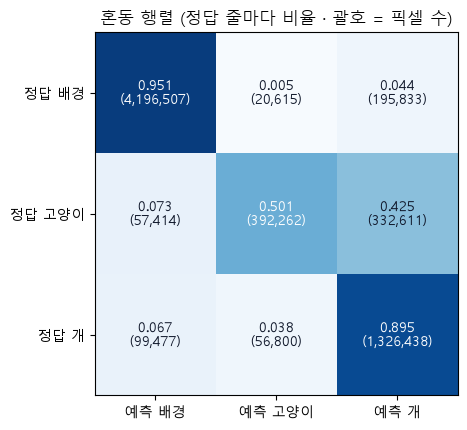

고양이 → 개 0.425 · 개 → 고양이 0.038


In [6]:
# 혼동 행렬 그림: 행 = 정답 · 열 = 예측 · 정답 줄마다 비율
import matplotlib.pyplot as plt  # 그림

plt.rcParams["font.family"] = "Malgun Gothic"                          # 한글
plt.rcParams["axes.unicode_minus"] = False                             # 음수 기호
rate = cm3.float() / cm3.sum(1, keepdim=True).float()                  # 정답 줄마다 합 1
fig, ax = plt.subplots(figsize=(5.2, 4.4))                             # 그림 크기
ax.imshow(rate, cmap="Blues", vmin=0, vmax=1)                          # 진할수록 많음
for r in range(3):                                                     # 정답 줄
    for k in range(3):                                                 # 예측 칸
        label = f"{rate[r, k]:.3f}\n({int(cm3[r, k]):,})"              # 비율 · 픽셀 수
        ax.text(k, r, label, ha="center", va="center", fontsize=10,    # 칸 가운데
                color="white" if rate[r, k] > 0.5 else "#0f172a")      # 진한 칸은 흰 글자
ax.set_xticks(range(3), [f"예측 {n}" for n in CLASSES], fontsize=10)   # 열 이름
ax.set_yticks(range(3), [f"정답 {n}" for n in CLASSES], fontsize=10)   # 행 이름
ax.set_title("혼동 행렬 (정답 줄마다 비율 · 괄호 = 픽셀 수)", fontsize=12)  # 제목
plt.tight_layout()                                                     # 여백
plt.show()                                                             # 표시
print(f"고양이 → 개 {rate[1, 2]:.3f} · 개 → 고양이 {rate[2, 1]:.3f}")  # 2클래스에서는 볼 수 없던 칸

**결과** · 예측 정답은 고양이 → 개 (0.425) — 개 → 고양이는 0.038

- 그림: 대각선이 진함 · 고양이 행의 개 칸이 두 번째로 진함
- `고양이 → 개 0.425 · 개 → 고양이 0.038` — 원본 22.5% · 3.9% · 같은 방향으로 치우침

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류의 혼동 행렬</td>
<td style="text-align: left;">단위 = 사진</td>
<td style="text-align: left;">분류 모델</td>
</tr>
<tr>
<td style="text-align: left;">분할의 혼동 행렬</td>
<td style="text-align: left;">단위 = 픽셀 · 255 뺌</td>
<td style="text-align: left;">클래스별 IoU의 재료</td>
</tr>
<tr>
<td style="text-align: left;">2클래스 혼동 행렬</td>
<td style="text-align: left;">동물 ↔ 배경만</td>
<td style="text-align: left;">종 혼동은 안 보임</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 비율은 정답 줄마다 나눔 (열로 나누면 정밀도가 됨)

> ✅ **한 줄 정리** · 분할의 혼동 행렬은 픽셀 단위로 행 = 정답 · 열 = 예측이며, 3클래스부터 종을 헷갈린 칸이 보인다.

**딥러닝 코드에서는**

- `cm = torch.bincount(y * C + pred, minlength=C * C).reshape(C, C)` — 255는 먼저 뺌

---
## 2. 증강: 정답 지도도 같이

> **이 장의 흐름**
>
> - 분류는 뒤집어도 정답 '개' 그대로 · 분할은 정답이 사진 위의 자리
> - 자리를 바꾸는 변환은 함께 · 값은 번호로 · 빈 자리는 255 · 작은 물체는 남았는지

<img src="images/sf2_aug.png" alt="변환별로 정답 지도에 해야 할 일" width="763">

**파이프라인 위치** · ① 데이터 (증강)

### 2-1. `A` 사진만 뒤집으면 · `photo[:, ::-1]` · `IoU` <sub>Day02 In[56] · In[57]</sub>

> 🎯 **사진만 좌우로 뒤집고 정답은 그대로 두면 무엇이 잘못을 알려 주는가?**

💡 **쉽게 말하면**

- 모양 · 값 개수가 같아 **에러가 안 남**.
- 그대로 둔 정답과 진짜 정답의 **IoU를 재야** 보임.

**실행 흐름**

1. 사진만 뒤집기
2. 모양 · 값 개수 비교
3. 진짜 정답(같이 뒤집은 것)과 IoU

**먼저 예측** · 그대로 둔 정답과 진짜 정답의 동물 IoU는 1에 가까울까? — 답은 코드 실행 결과 아래에

In [7]:
# 사진만 뒤집고 정답은 그대로 두면? (에러가 나지 않음 → 숫자로 확인)
photo, target = load_pair("saint_bernard_146", three=False)         # 224×224 · 정답 0 · 1 · 255
photo_only = photo[:, ::-1].copy()                                  # 사진만 좌우 뒤집기
print("모양:", photo_only.shape, "·", target.shape, "→ 에러 없음")  # 모양은 같음
counts = [int((target == v).sum()) for v in (0, 1, IGNORE)]         # 값별 픽셀 수
print("정답 값 0 · 1 · 255 개수:", counts)                          # 개수도 같음

both = target[:, ::-1]                                    # 뒤집은 사진의 진짜 정답
pet = ((target == 1) & (both == 1)).sum() / ((target == 1) | (both == 1)).sum()  # 동물 IoU
print(f"그대로 둔 정답 ↔ 진짜 정답 동물 IoU: {pet:.2f}")  # 1보다 훨씬 작음

모양: (224, 224, 3) · (224, 224) → 에러 없음
정답 값 0 · 1 · 255 개수: [35166, 10804, 4206]
그대로 둔 정답 ↔ 진짜 정답 동물 IoU: 0.43


**결과** · 예측 정답은 아님 — 0.43 (절반 이상 어긋남)

- `모양: (224, 224, 3) · (224, 224) → 에러 없음` — 코드는 그대로 돌아감
- `정답 값 0 · 1 · 255 개수: [35166, 10804, 4206]` — 원본과 같은 수
- `그대로 둔 정답 ↔ 진짜 정답 동물 IoU: 0.43` — 원본과 같은 값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류 증강</td>
<td style="text-align: left;">정답 라벨은 그대로</td>
<td style="text-align: left;">사진만 바꿈</td>
</tr>
<tr>
<td style="text-align: left;">분할 증강 (자리 변환)</td>
<td style="text-align: left;">사진 · 정답을 같은 변환으로</td>
<td style="text-align: left;">뒤집기 · 회전 · 자르기 · 크기</td>
</tr>
<tr>
<td style="text-align: left;">분할 증강 (값 변환)</td>
<td style="text-align: left;">정답은 그대로</td>
<td style="text-align: left;">밝기 · 색조</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 증강 버그는 에러 없이 성능만 떨어뜨림 → 겹쳐 그려 눈으로 확인

> ✅ **한 줄 정리** · 분할에서 사진만 뒤집으면 에러 없이 정답이 어긋나므로, 자리를 바꾸는 증강은 정답 지도에도 똑같이 적용해야 한다.

**딥러닝 코드에서는**

- 증강 직후 한 배치를 사진 위에 정답 윤곽선으로 그려 보기

### 2-2. `A` v2 · Image · Mask · `tv_tensors.Image` · `tv_tensors.Mask` · `v2.Resize` <sub>Day02 In[58] · In[59]</sub>

> 🎯 **v2 변환에 사진 · 정답 텐서를 그냥 같이 넣으면 둘 다 바뀌는가?**

💡 **쉽게 말하면**

- 그냥 텐서 여러 개면 **첫째만 사진**으로 보고 나머지는 그대로.
- `Mask`로 감싸면 '이건 정답 지도' → **같이 · 번호로** 다룸.

**실행 흐름**

1. 그냥 텐서 두 개로 뒤집기
2. Image · Mask로 감싸 뒤집기
3. Mask와 그냥 bilinear로 줄이기

**먼저 예측** · bilinear를 지정한 Resize에 Mask를 넣으면 값이 섞일까? — 답은 코드 실행 결과 아래에

In [8]:
# torchvision v2: 그냥 텐서 vs Image · Mask로 감싸기 · Mask 크기 조정
from torchvision import tv_tensors     # 사진 · 정답 타입
from torchvision.transforms import v2  # 변환 (사진 · 정답 같이)

img_t = torch.tensor(photo).permute(2, 0, 1)  # (3, 224, 224)
mask_t = torch.tensor(target)[None]           # (1, 224, 224)
flip = v2.RandomHorizontalFlip(p=1.0)         # 늘 뒤집음 (확인용)


def flp(u, v):                         # u가 v를 좌우로 뒤집은 것인지
    return torch.equal(u, v.flip(-1))  # 같으면 True


a, b = flip(img_t, mask_t)  # 그냥 텐서 두 개
print("그냥 텐서    · 사진 뒤집힘", flp(a, img_t), "· 정답 뒤집힘", flp(b, mask_t))  # 정답 그대로
a, b = flip(tv_tensors.Image(img_t), tv_tensors.Mask(mask_t))                        # 타입으로 감쌈
print("Image + Mask · 사진 뒤집힘", flp(a, img_t), "· 정답 뒤집힘", flp(b, mask_t))  # 둘 다

small = v2.Resize((56, 56), interpolation=v2.InterpolationMode.BILINEAR)   # bilinear를 지정해도
_, b = small(tv_tensors.Image(img_t), tv_tensors.Mask(mask_t))             # Mask는 nearest로 처리
bil = F.interpolate(mask_t[None].float(), size=(56, 56), mode="bilinear")  # 그냥 bilinear
kinds_mask, kinds_bil = torch.unique(b).tolist(), len(torch.unique(bil))   # 값 종류
print("Mask로 줄임 → 값", kinds_mask, "· 그냥 bilinear → 값", kinds_bil, "가지")  # 번호가 섞이나

그냥 텐서    · 사진 뒤집힘 True · 정답 뒤집힘 False
Image + Mask · 사진 뒤집힘 True · 정답 뒤집힘 True
Mask로 줄임 → 값 [0, 1, 255] · 그냥 bilinear → 값 9 가지


**결과** · 예측 정답은 안 섞임 — Mask는 nearest로 처리 (값 3가지 그대로)

- `그냥 텐서    · 사진 뒤집힘 True · 정답 뒤집힘 False` — 에러 없이 정답만 그대로
- `Image + Mask · 사진 뒤집힘 True · 정답 뒤집힘 True` — 같이 뒤집힘
- `Mask로 줄임 → 값 [0, 1, 255] · 그냥 bilinear → 값 9 가지` — 번호 사이 값이 생기면 정답이 아님

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">그냥 텐서 여러 개</td>
<td style="text-align: left;">첫째만 변환</td>
<td style="text-align: left;">쓰지 않음</td>
</tr>
<tr>
<td style="text-align: left;"><code>tv_tensors.Image</code> + <code>Mask</code></td>
<td style="text-align: left;">자리 변환은 같이 · Mask는 nearest</td>
<td style="text-align: left;">분할 증강의 기본</td>
</tr>
<tr>
<td style="text-align: left;">직접 <code>F.interpolate</code></td>
<td style="text-align: left;">모드를 직접 골라야 함</td>
<td style="text-align: left;">마스크는 <code>mode="nearest"</code></td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 원본은 torchvision 0.29 · 이 노트북은 0.26 — 같은 결과지만 버전이 다르면 문서 확인

> ✅ **한 줄 정리** · v2에서는 정답을 tv_tensors.Mask로 감싸야 사진과 같은 자리 변환을 받고 값은 번호로(nearest) 유지된다.

**딥러닝 코드에서는**

- `v2.Compose([...])(tv_tensors.Image(x), tv_tensors.Mask(y))` — Dataset `__getitem__` 안에서

### 2-3. `A` 회전의 빈 자리 · `v2.RandomRotation(fill=…)` <sub>Day02 In[60]</sub>

> 🎯 **회전으로 생긴 정답의 빈 모서리를 0과 255 중 무엇으로 채워야 하는가?**

💡 **쉽게 말하면**

- 0으로 채우면 모델이 빈 모서리를 **'배경'이라고 배움**.
- 255로 채우면 손실 · 평가에서 **빠짐**.

**실행 흐름**

1. 25도 회전 · 채움 기본값 0
2. 사진 0 · 정답 255로 따로 채움
3. 배경 비율 비교

**먼저 예측** · 채움 0과 255에서 배경 비율은 어떻게 다를까? — 답은 코드 실행 결과 아래에

배경 비율: 원래 0.70 · 채움 0 0.70 · 채움 255 0.56


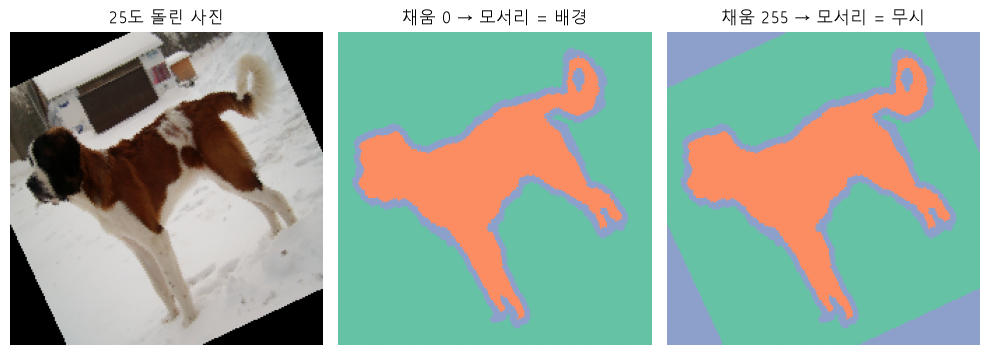

In [9]:
# 회전의 빈 자리: 정답을 0(배경)으로 채울까 255(무시)로 채울까
rot0 = v2.RandomRotation(degrees=(25, 25))                            # 늘 25도 · 채움 기본값 0
_, m0 = rot0(tv_tensors.Image(img_t), tv_tensors.Mask(mask_t))        # 빈 모서리 = 배경
fills = {tv_tensors.Image: 0, tv_tensors.Mask: IGNORE}                # 사진 0 · 정답 255
rot255 = v2.RandomRotation(degrees=(25, 25), fill=fills)              # 타입마다 따로 채움
r_img, m1 = rot255(tv_tensors.Image(img_t), tv_tensors.Mask(mask_t))  # 빈 모서리 = 무시

bg = [(m == 0).float().mean().item() for m in (mask_t, m0, m1)]                # 배경 픽셀 비율
print("배경 비율: 원래 {:.2f} · 채움 0 {:.2f} · 채움 255 {:.2f}".format(*bg))  # 0이면 가짜 배경


def paint(m):                                 # 색칠용: 255 → 2
    return np.where(m[0] == IGNORE, 2, m[0])  # 0 배경 · 1 동물 · 2 무시


fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))      # 사진 · 정답 2개
ax[0].imshow(r_img.permute(1, 2, 0))                 # 돌린 사진
ax[0].set_title("25도 돌린 사진", fontsize=12)       # 빈 모서리 = 검정
pairs = [(ax[1], m0, "채움 0 → 모서리 = 배경"), (ax[2], m1, "채움 255 → 모서리 = 무시")]  # 정답 2개
for a, m, t in pairs:                                # 칸마다
    a.imshow(paint(m), cmap="Set2", vmin=0, vmax=7)  # 0 배경 · 1 동물 · 2 무시
    a.set_title(t, fontsize=12)                      # 제목
for a in ax:                                         # 축 지우기
    a.axis("off")                                    # 눈금 없음
plt.tight_layout()                                   # 여백
plt.show()                                           # 표시

**결과** · 예측 정답은 0이면 0.70 그대로(가짜 배경이 섞임) · 255면 0.56

- `배경 비율: 원래 0.70 · 채움 0 0.70 · 채움 255 0.56` — 원본과 같은 값
- 그림: 채움 0은 모서리가 배경색 · 채움 255는 모서리가 무시 색

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">채움 0 (기본값)</td>
<td style="text-align: left;">빈 자리 = 배경 클래스</td>
<td style="text-align: left;">배경이 정말로 이어지는 사진</td>
</tr>
<tr>
<td style="text-align: left;">채움 255 (ignore)</td>
<td style="text-align: left;">빈 자리 = 손실 · 평가에서 뺌</td>
<td style="text-align: left;">보통 이쪽 (원본 권장)</td>
</tr>
<tr>
<td style="text-align: left;">사진의 빈 자리</td>
<td style="text-align: left;">0(검정) · 값만</td>
<td style="text-align: left;">정답과 따로 정함</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `fill`은 dict로 타입마다 따로 (`{tv_tensors.Image: 0, tv_tensors.Mask: 255}`)

> ✅ **한 줄 정리** · 회전 · 이동으로 생긴 정답의 빈 자리는 255로 채워 손실과 평가에서 빼야 가짜 배경을 배우지 않는다.

**딥러닝 코드에서는**

- `CrossEntropyLoss(ignore_index=255)`와 같은 번호를 써야 실제로 빠짐

### 2-4. `B` 무작위 자르기와 작은 물체 · `v2.RandomCrop` <sub>Day02 In[61] · In[62] (원본: 미션 사진의 공)</sub>

> 🎯 **큰 사진을 무작위로 자르면 작은 물체(공)는 얼마나 자주 남는가?**

💡 **쉽게 말하면**

- 자른 범위 밖의 공은 **정답에서 사라짐**.
- 자를 때마다 공이 남았는지 **세어 봄**.

**실행 흐름**

1. 360×640 지도에 지름 16 공
2. 256×256으로 200번 자르기
3. 공이 남은 횟수

**먼저 예측** · 200번 중 공이 남은 비율은 절반을 넘을까? — 답은 코드 실행 결과 아래에

In [10]:
# 무작위 자르기: 작은 물체(공)가 잘린 범위에 남는가 (원본: 미션 사진 · 여기서는 직접 그린 경기장)
from PIL import ImageDraw  # 도형 그리기

field = Image.new("L", (640, 360), 0)                           # 360×640 정답 지도 (0 = 공 아님)
ImageDraw.Draw(field).ellipse((480, 60, 496, 76), fill=1)       # 지름 16 공 하나 (오른쪽 위)
ball = tv_tensors.Mask(torch.tensor(np.array(field)))           # 공 자리만 1
photo_f = tv_tensors.Image(torch.zeros(3, 360, 640, dtype=torch.uint8))  # 사진 자리 (값은 상관없음)
crop = v2.RandomCrop(256)                                       # 256×256 무작위 자르기
torch.manual_seed(0)                                            # 자르는 자리 고정
kept = [int(crop(photo_f, ball)[1].sum()) for _ in range(200)]  # 200번 자르고 남은 공 픽셀
n = sum(k > 0 for k in kept)                                    # 공이 조금이라도 남은 횟수
print(f"공 픽셀 {int(ball.sum())}개 · 256×256으로 200번 자름",  # 대부분 사라짐
      f"→ 공이 남은 것 {n}번 ({n / 200:.0%})")
print("전부 남은 것:", sum(k == int(ball.sum()) for k in kept), "번")  # 잘려서 일부만 남기도 함

공 픽셀 221개 · 256×256으로 200번 자름 → 공이 남은 것 65번 (32%)
전부 남은 것: 41 번


**결과** · 예측 정답은 안 넘음 — 32% (원본 미션 사진 26%)

- `공 픽셀 221개 · 256×256으로 200번 자름 → 공이 남은 것 65번 (32%)` — 원본: 미션 사진의 공 · 더 큰 자르기 · 26%
- `전부 남은 것: 41 번` — 나머지 24번은 공이 잘려 일부만

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">무작위 자르기</td>
<td style="text-align: left;">다양한 위치 · 작은 물체가 자주 사라짐</td>
<td style="text-align: left;">큰 물체 위주 데이터</td>
</tr>
<tr>
<td style="text-align: left;">물체 중심 자르기</td>
<td style="text-align: left;">작은 클래스가 범위에 들게</td>
<td style="text-align: left;">공처럼 드문 클래스</td>
</tr>
<tr>
<td style="text-align: left;">밝기 · 색조</td>
<td style="text-align: left;">자리는 그대로 · 정답 그대로</td>
<td style="text-align: left;">단, 색이 곧 클래스면 위험 (팀 유니폼 색)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 색 바꾸기도 항상 안전하지 않음 — 미션의 Team A · B처럼 색으로 구분하는 클래스

> ✅ **한 줄 정리** · 무작위 자르기는 작은 물체를 정답에서 자주 지우므로, 자른 범위에 작은 클래스가 남는지 세어 보고 정해야 한다.

**딥러닝 코드에서는**

- 증강 기준은 변환의 이름이 아니라 '정답의 의미가 유지되는가'

---
## 3. 작은 클래스와 Dice

> **이 장의 흐름**
>
> - 픽셀 비율이 작으면 CE 평균에서 그 클래스의 손실이 묻힘
> - Dice는 클래스마다 겹침을 따로 셈 → 손실로 쓸 때는 확률로 계산한 soft Dice

<img src="images/sf2_small.png" alt="32×32 장난감: 예측 A · B · C의 CE 평균과 Dice" width="763">

**파이프라인 위치** · ③ 손실 → ⑥ 평가

### 3-1. `A` 클래스별 픽셀 비율 · `torch.bincount` <sub>Day02 In[17] · In[18] (원본: 미션 100장의 공 0.13%)</sub>

> 🎯 **학습 정답에서 클래스마다 픽셀이 얼마나 차지하는가?**

💡 **쉽게 말하면**

- 손실은 **픽셀마다** 셈 → 픽셀이 적은 클래스는 **목소리가 작음**.

**실행 흐름**

1. 255 뺀 픽셀을 클래스별로 셈
2. 비율 · 경계 비율
3. 학습 사진 수

**먼저 예측** · 고양이 픽셀은 개 픽셀보다 많을까? — 답은 코드 실행 결과 아래에

In [11]:
# 작은 클래스는 손실에서 얼마나 작나: 학습 정답의 클래스별 픽셀 비율
cnt = torch.bincount(Ytr[Ytr != IGNORE], minlength=3).float()  # 경계 뺀 픽셀 수
for k, name in enumerate(CLASSES):                             # 클래스별
    print(f"{name}: {cnt[k] / cnt.sum():.3f}")                 # 비율
print(f"경계(255) 픽셀: {(Ytr == IGNORE).float().mean():.3f} (손실 · 평가에서 뺌)")  # 무시 비율
cat_imgs = sum(SPECIES[n] == 1 for n in TRAIN[:1200])          # 학습 사진 중 고양이
print(f"학습 사진: 고양이 {cat_imgs} · 개 {1200 - cat_imgs}")  # 사진 수부터 차이

배경: 0.661
고양이: 0.128
개: 0.211
경계(255) 픽셀: 0.118 (손실 · 평가에서 뺌)
학습 사진: 고양이 413 · 개 787


**결과** · 예측 정답은 적음 — 0.128 vs 0.211 (사진 수부터 413 vs 787)

- `배경: 0.661` — 가장 많음
- `고양이: 0.128` — 개의 약 60%
- `개: 0.211` — 
- `학습 사진: 고양이 413 · 개 787` — 1-3에서 고양이 IoU가 낮은 후보 원인

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Oxford Pet 3클래스</td>
<td style="text-align: left;">가장 작은 클래스 12.8%</td>
<td style="text-align: left;">약한 불균형</td>
</tr>
<tr>
<td style="text-align: left;">미션 football</td>
<td style="text-align: left;">공 약 0.13% · 잔디 약 40%</td>
<td style="text-align: left;">심한 불균형 (원본 표)</td>
</tr>
<tr>
<td style="text-align: left;">먼저 볼 것</td>
<td style="text-align: left;">정답에 작은 클래스가 남아 있는가</td>
<td style="text-align: left;">6-2 칠하는 순서</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 작은 클래스를 못 찾으면 모델보다 **정답부터** 의심 (칠하는 순서 · 자르기에서 사라졌는지)

> ✅ **한 줄 정리** · 분할 손실은 픽셀마다 계산하므로 픽셀 비율이 작은 클래스는 손실 평균에서 목소리가 작다.

**딥러닝 코드에서는**

- 클래스별 픽셀 수 → `CrossEntropyLoss(weight=...)` 가중치 후보 (비교 실험으로 결정)

### 3-2. `A` CE 평균 vs Dice (장난감) · `reduction="none"` · `soft Dice` <sub>Day02 In[19]</sub>

> 🎯 **물체를 통째로 놓친 예측 A와 물체를 크게 칠한 C 중 CE 평균이 작은 쪽은?**

💡 **쉽게 말하면**

- 9픽셀 물체의 큰 손실이 배경 1,015픽셀의 **작은 손실에 묻힘**.
- Dice는 **물체 클래스만** 보고 겹침을 셈.

**실행 흐름**

1. 32×32 정답에 3×3 물체
2. 예측 A · B · C 점수 만들기
3. CE 평균 · 물체 픽셀 CE · soft Dice

**먼저 예측** · A(전부 배경)의 CE 평균은 C보다 클까? — 답은 코드 실행 결과 아래에

In [12]:
# 장난감 32×32: 3×3 물체(9픽셀 · 0.9%) · 예측 A 전부 배경 · B 정확히 · C 7×7로 크게
toy_t = torch.zeros(32, 32, dtype=torch.long)  # 정답 지도
toy_t[14:17, 14:17] = 1                        # 물체 9픽셀


def toy_logits(obj):                   # 물체라고 본 자리 [0, 8] · 나머지 [8, 0]
    lg = torch.zeros(2, 32, 32)        # (클래스, H, W)
    lg[0] = 8.0                        # 기본: 배경 확신
    lg[0][obj], lg[1][obj] = 0.0, 8.0  # 물체 자리: 물체 확신
    return lg                          # 점수


def soft_dice(p, t):                                         # 확률로 계산한 물체 Dice
    return (2 * (p * t).sum() / (p.sum() + t.sum())).item()  # 2·겹침 ÷ (예측 + 정답)


exact = toy_t == 1                                                              # 정확한 물체 자리
big = torch.zeros(32, 32, dtype=torch.bool)                                     # 7×7 = 49픽셀
big[12:19, 12:19] = True                                                        # 둘레까지 크게
print("예측           | CE 평균 | 물체 픽셀 CE | 물체 soft Dice")               # 머리
cases = [("A 전부 배경  ", torch.zeros_like(exact)), ("B 정확히     ", exact),  # 놓침 · 정확
         ("C 7×7로 크게", big)]                                                 # 넘치게
for name, m in cases:                                                           # 예측 세 가지
    lg = toy_logits(m)                                                          # 예측 점수
    ce = F.cross_entropy(lg[None], toy_t[None], reduction="none")[0]            # 픽셀별 CE 지도
    dice = soft_dice(lg.softmax(0)[1], exact.float())                           # 물체 확률로 Dice
    print(f"{name}   | {ce.mean():.3f}   | {ce[exact].mean():.3f}        | {dice:.3f}")  # 한 줄

예측           | CE 평균 | 물체 픽셀 CE | 물체 soft Dice
A 전부 배경     | 0.071   | 8.000        | 0.001
B 정확히        | 0.000   | 0.000        | 0.981
C 7×7로 크게   | 0.313   | 0.000        | 0.309


**결과** · 예측 정답은 작음 — A 0.071 < C 0.313 (물체를 놓쳤는데도)

- `A 전부 배경     | 0.071   | 8.000        | 0.001` — 물체 픽셀 손실은 8인데 평균은 작음
- `B 정확히        | 0.000   | 0.000        | 0.981` — 둘 다 최고
- `C 7×7로 크게   | 0.313   | 0.000        | 0.309` — 물체는 찾았지만 넘친 40픽셀이 벌점

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">CE 평균</td>
<td style="text-align: left;">픽셀 하나하나 · 평균</td>
<td style="text-align: left;">기본 손실 · 작은 클래스가 묻힘</td>
</tr>
<tr>
<td style="text-align: left;">Dice</td>
<td style="text-align: left;">클래스마다 겹침 전체</td>
<td style="text-align: left;">작은 클래스가 덜 묻힘</td>
</tr>
<tr>
<td style="text-align: left;">CE + Dice</td>
<td style="text-align: left;">둘을 더해 씀</td>
<td style="text-align: left;">섞는 비율은 직접 정함</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - Dice 손실은 확률을 받음 (softmax를 먼저) · CE는 logits를 받음

> ✅ **한 줄 정리** · CE 평균은 작은 물체를 통째로 놓쳐도 작게 나올 수 있고, Dice는 클래스별 겹침으로 그 실패를 드러낸다.

**딥러닝 코드에서는**

- `loss = F.cross_entropy(out, y) + (1 - soft_dice)` — 비율은 실험으로

### 3-3. `A` IoU와 Dice · `2·TP ÷ (2·TP + FP + FN)` <sub>Day02 In[20]</sub>

> 🎯 **같은 TP · FP · FN에서 IoU와 Dice는 어떤 관계인가?**

💡 **쉽게 말하면**

- 둘 다 **겹친 넓이**로 셈.
- Dice는 겹침을 **두 번** 세서 IoU보다 큼.

**실행 흐름**

1. TP 4 · FP 5 · FN 5
2. IoU · Dice 계산
3. 2·IoU ÷ (1 + IoU)와 비교

**먼저 예측** · IoU 0.29일 때 Dice는? — 답은 코드 실행 결과 아래에

In [13]:
# Dice와 IoU: 같은 TP · FP · FN으로 셈 (Day1의 6×6 장난감)
TP, FP, FN = 4, 5, 5                # 겹침 · 잘못 칠함 · 놓침
iou = TP / (TP + FP + FN)           # IoU
dice = 2 * TP / (2 * TP + FP + FN)  # Dice
from_iou = 2 * iou / (1 + iou)      # IoU로 Dice 계산
print(f"IoU {iou:.2f} · Dice {dice:.2f} · 2·IoU ÷ (1 + IoU) = {from_iou:.2f}")  # 같은 정보

IoU 0.29 · Dice 0.44 · 2·IoU ÷ (1 + IoU) = 0.44


**결과** · 예측 정답은 0.44 = 2 × 0.29 ÷ 1.29

- `IoU 0.29 · Dice 0.44 · 2·IoU ÷ (1 + IoU) = 0.44` — 원본과 같은 값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">IoU</td>
<td style="text-align: left;">TP ÷ (TP + FP + FN)</td>
<td style="text-align: left;">분할 보고의 기본 (mIoU)</td>
</tr>
<tr>
<td style="text-align: left;">Dice</td>
<td style="text-align: left;">2·TP ÷ (2·TP + FP + FN)</td>
<td style="text-align: left;">의료 영상 · 손실</td>
</tr>
<tr>
<td style="text-align: left;">관계</td>
<td style="text-align: left;">Dice = 2·IoU ÷ (1 + IoU)</td>
<td style="text-align: left;">한 클래스 · 같은 마스크일 때만</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - mIoU와 Dice 평균 사이에는 이 식을 그대로 못 씀 (평균을 먼저 했으므로)

> ✅ **한 줄 정리** · 한 클래스에서 Dice는 2·IoU ÷ (1 + IoU)로 IoU와 같은 정보를 다른 눈금으로 나타낸다.

**딥러닝 코드에서는**

- 보고할 지표 하나를 정하고 일관되게 (미션: mIoU)

### 3-4. `A` soft Dice 손실 · `argmax` · `grad_fn` · `softmax` <sub>Day02 In[21]</sub>

> 🎯 **왜 지표 Dice를 그대로 손실로 쓸 수 없고 'soft' Dice를 쓰는가?**

💡 **쉽게 말하면**

- argmax로 0/1을 만들면 **기울기가 끊김**.
- 확률을 그대로 넣어 계산하면 **미분 가능**.

**실행 흐름**

1. C 예측 점수에 기울기 추적
2. argmax의 grad_fn 확인
3. 확률로 soft Dice → backward

**먼저 예측** · argmax 결과의 grad_fn은? — 답은 코드 실행 결과 아래에

In [14]:
# 지표 Dice → 손실: argmax는 기울기가 끊기므로 확률로 계산한 soft Dice
lg = toy_logits(big).clone().requires_grad_(True)                        # C 예측 · 기울기 추적
hard = lg.argmax(0)                                                      # 0/1로 자른 예측
print("argmax 결과의 grad_fn:", hard.grad_fn)                            # None → 손실로 못 씀
p_obj = lg.softmax(0)[1]                                                 # 물체 확률 (그대로 둠)
loss_dice = 1 - 2 * (p_obj * exact).sum() / (p_obj.sum() + exact.sum())  # soft Dice 손실
loss_dice.backward()                                                     # 역전파
print(f"soft Dice 손실 {loss_dice.item():.3f} · 기울기 있음: {lg.grad is not None}")  # 학습 가능

argmax 결과의 grad_fn: None
soft Dice 손실 0.691 · 기울기 있음: True


**결과** · 예측 정답은 None — 기울기가 이어지지 않음

- `argmax 결과의 grad_fn: None` — 손실로 못 씀
- `soft Dice 손실 0.691 · 기울기 있음: True` — 1 - 0.309 · 학습 가능

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">지표 Dice</td>
<td style="text-align: left;">argmax 0/1로 셈 · 보고용</td>
<td style="text-align: left;">평가</td>
</tr>
<tr>
<td style="text-align: left;">soft Dice 손실</td>
<td style="text-align: left;">확률로 셈 · 미분 가능</td>
<td style="text-align: left;">학습</td>
</tr>
<tr>
<td style="text-align: left;">라이브러리 Dice 손실</td>
<td style="text-align: left;">입력이 logits인지 확률인지 다름</td>
<td style="text-align: left;">문서 확인</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 미션 문서의 'Dice Loss … 평가 지표' → 손실로 쓰는지 지표로 보고하는지 따로 적기

> ✅ **한 줄 정리** · argmax는 기울기를 끊으므로 Dice를 손실로 쓰려면 확률로 계산한 soft Dice를 써야 한다.

**딥러닝 코드에서는**

- `p = out.softmax(1)` → 클래스별 `1 - 2·(p·y).sum() ÷ (p.sum() + y.sum())` 평균

---
## 4. 클래스별로 어디서 틀리나

> **이 장의 흐름**
>
> - 클래스별 IoU → 혼동 행렬 → 많이 틀린 사진 순서로 좁혀 감
> - 본 것(관찰)과 짐작(후보 원인)을 나누고 확인 방법을 함께 적음

<img src="images/sf2_errors.png" alt="오류 분석 순서와 관찰 · 후보 원인 · 확인 방법" width="763">

**파이프라인 위치** · ⑥ 평가 → 분석

### 4-1. `A` 종을 틀린 사진 찾기 · `flatten(1).sum(1)` · `argsort` <sub>Day02 In[22] · In[23]</sub>

> 🎯 **사진마다 '종을 틀린 동물 픽셀' 비율을 구하면 어떤 사진이 위에 오는가?**

💡 **쉽게 말하면**

- 사진마다 **동물 픽셀 중 종을 틀린 비율**.
- 큰 순서로 **몇 장을 직접 봄**.

**실행 흐름**

1. 사진마다 고양이→개 · 개→고양이 픽셀
2. 동물 픽셀로 나눈 비율
3. 많이 틀린 6장 출력 · 그림

**먼저 예측** · 가장 많이 틀린 사진은 고양이일까 개일까? — 답은 코드 실행 결과 아래에

검증 460장 중 종을 틀린 비율 10% 초과 113장 · 50% 초과 72장
Siamese_114            틀린 비율 1.00 (고양이→개 3,576 · 개→고양이 0)
Sphynx_199             틀린 비율 1.00 (고양이→개 6,520 · 개→고양이 0)
Birman_151             틀린 비율 1.00 (고양이→개 2,199 · 개→고양이 0)
Bombay_102             틀린 비율 1.00 (고양이→개 4,938 · 개→고양이 0)
Siamese_175            틀린 비율 1.00 (고양이→개 4,534 · 개→고양이 0)
Bengal_128             틀린 비율 1.00 (고양이→개 6,762 · 개→고양이 0)


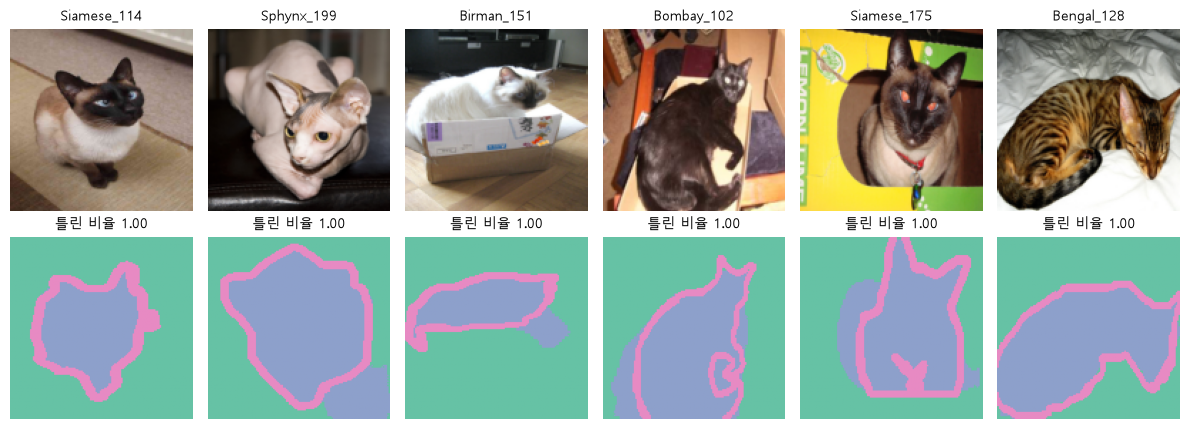

In [15]:
# 사진마다 '종을 틀린 동물 픽셀' 비율 → 많이 틀린 사진부터 보기
cat_as_dog = ((Yva == 1) & (P3 == 2)).flatten(1).sum(1)            # 사진마다 고양이 → 개
dog_as_cat = ((Yva == 2) & (P3 == 1)).flatten(1).sum(1)            # 개 → 고양이
pet_px = ((Yva == 1) | (Yva == 2)).flatten(1).sum(1).clamp_min(1)  # 동물 픽셀 (0 나눗셈 방지)
mix = (cat_as_dog + dog_as_cat).float() / pet_px.float()           # 종을 틀린 비율
n10, n50 = int((mix > 0.1).sum()), int((mix > 0.5).sum())          # 10% · 50% 넘는 사진 수
print(f"검증 {len(VAL)}장 중 종을 틀린 비율 10% 초과 {n10}장 · 50% 초과 {n50}장")  # 분포
worst = torch.argsort(mix, descending=True)[:6].tolist()           # 가장 많이 틀린 6장
for j in worst:                                                    # 한 줄씩
    c2d, d2c = int(cat_as_dog[j]), int(dog_as_cat[j])              # 두 방향 픽셀
    print(f"{VAL[j]:22} 틀린 비율 {mix[j]:.2f} (고양이→개 {c2d:,} · 개→고양이 {d2c:,})")  # 한 장

fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))                 # 위: 사진 · 아래: 예측
for c, j in enumerate(worst):                                   # 6장
    ax[0, c].imshow(load_pair(VAL[j], 128)[0])                  # 사진
    ax[0, c].set_title(VAL[j][:14], fontsize=10)                # 이름
    shown = torch.where(Yva[j] == IGNORE, 3, P3[j])             # 예측 (경계 자리는 3)
    ax[1, c].imshow(shown, cmap="Set2", vmin=0, vmax=7)         # 번호별 색
    ax[1, c].set_title(f"틀린 비율 {mix[j]:.2f}", fontsize=10)  # 비율
for a in ax.flat:                                               # 축 지우기
    a.axis("off")                                               # 눈금 없음
plt.tight_layout()                                              # 여백
plt.show()                                                      # 표시

**결과** · 예측 정답은 고양이 — 위 6장 모두 고양이 한 마리 전체를 개로

- `검증 460장 중 종을 틀린 비율 10% 초과 113장 · 50% 초과 72장` — 원본도 같은 경향 (검증의 약 24% · 7%)
- `Siamese_114            틀린 비율 1.00 (고양이→개 3,576 · 개→고양이 0)` — 한 마리 전체를 개로
- 그림 색: 초록 배경 · 주황 고양이 · 파랑 개 · 분홍 경계 — 6장 모두 모양은 맞고 색이 파랑(개)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">관찰 (본 것)</td>
<td style="text-align: left;">고양이 한 마리 전체를 개로 칠함</td>
<td style="text-align: left;">그림 · 숫자 그대로</td>
</tr>
<tr>
<td style="text-align: left;">후보 원인 (확인 전)</td>
<td style="text-align: left;">고양이 사진이 적음 · 품종 · 털색</td>
<td style="text-align: left;">하나로 정하지 않음</td>
</tr>
<tr>
<td style="text-align: left;">확인 방법</td>
<td style="text-align: left;">품종별 IoU · 학습 사진 수 · 가중치 바꿔 비교</td>
<td style="text-align: left;">한 번에 하나씩</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 많이 틀린 사진은 대표 사진이 아님 — 비율 분포(10% · 50% 초과 장수)와 함께 보기

> ✅ **한 줄 정리** · 오류 분석은 클래스별 IoU → 혼동 행렬 → 많이 틀린 사진 순으로 좁히고, 관찰과 후보 원인을 나눠 적는다.

**딥러닝 코드에서는**

- 미션도 같은 순서: 클래스별 IoU → 혼동 행렬 → 많이 틀린 사진 → 관찰 / 후보 원인 / 확인 방법

---
## 5. 붙어 있는 여러 마리: instance

> **이 장의 흐름**
>
> - semantic 지도에는 개체 번호가 없음 → 붙은 두 마리는 한 덩어리
> - Mask R-CNN은 박스마다 마스크 · 두 기준(탐지 점수 · 마스크 확률)으로 결과를 고름

<img src="images/sf2_instance.png" alt="semantic 덩어리 1개 vs Mask R-CNN 개체별 결과 · 두 기준" width="763">

**파이프라인 위치** · ② 모델 → ⑤ 후처리

### 5-1. `A` 덩어리 세기 · `deque` · `연결 요소` <sub>Day02 In[24]</sub>

> 🎯 **개가 여러 마리인 사진의 semantic 정답에서 동물 덩어리는 몇 개인가?**

💡 **쉽게 말하면**

- 닿아 있는 동물 픽셀을 **한 덩어리**로 셈.
- 붙은 개체는 **하나**로 세어짐.

**실행 흐름**

1. 원본 크기 trimap 열기
2. 상하좌우로 퍼지며 덩어리 세기

**먼저 예측** · leonberger_107의 동물 덩어리 수는? — 답은 코드 실행 결과 아래에

In [16]:
# semantic 정답으로 '몇 마리?'에 답할 수 있나: 붙어 있는 픽셀 덩어리 세기
from collections import deque  # 너비 우선 탐색


def count_blobs(mask):                                            # 상하좌우로 닿은 True 덩어리 수
    seen, n = np.zeros_like(mask, dtype=bool), 0                  # 방문 표시 · 개수
    for y, x in zip(*np.nonzero(mask)):                           # True 픽셀마다
        if seen[y, x]:                                            # 이미 센 덩어리
            continue                                              # 건너뜀
        n += 1                                                    # 새 덩어리
        seen[y, x], q = True, deque([(y, x)])                     # 시작점
        while q:                                                  # 이웃으로 퍼짐
            cy, cx = q.popleft()                                  # 꺼내기
            for ny, nx in ((cy - 1, cx), (cy + 1, cx), (cy, cx - 1), (cy, cx + 1)):  # 상하좌우
                inside = 0 <= ny < mask.shape[0] and 0 <= nx < mask.shape[1]  # 지도 안
                if inside and mask[ny, nx] and not seen[ny, nx]:  # 동물 · 처음
                    seen[ny, nx] = True                           # 방문
                    q.append((ny, nx))                            # 다음 차례
    return n                                                      # 덩어리 수


inst_name = "leonberger_107"         # 개 여러 마리 · 사람이 있는 사진
inst_photo = np.array(Image.open(DATA / "images" / f"{inst_name}.jpg").convert("RGB"))  # 원본 크기
inst_tri = np.array(Image.open(DATA / "annotations" / "trimaps" / f"{inst_name}.png"))  # 원본 정답
n_blob = count_blobs(inst_tri == 1)  # 동물 픽셀 덩어리
print("사진 크기:", inst_photo.shape, "· 동물(값 1) 덩어리 수:", n_blob)  # 개체 수가 아님

사진 크기: (500, 333, 3) · 동물(값 1) 덩어리 수: 1


**결과** · 예측 정답은 1개 — 실제 개는 여러 마리

- `사진 크기: (500, 333, 3) · 동물(값 1) 덩어리 수: 1` — 원본과 같은 값 · 개체 수가 아님

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">semantic 덩어리 세기</td>
<td style="text-align: left;">닿은 픽셀 = 한 개체</td>
<td style="text-align: left;">떨어져 있는 개체만 셀 수 있음</td>
</tr>
<tr>
<td style="text-align: left;">instance (Mask R-CNN)</td>
<td style="text-align: left;">개체마다 마스크</td>
<td style="text-align: left;">붙은 개체도 따로</td>
</tr>
<tr>
<td style="text-align: left;">Oxford 정답</td>
<td style="text-align: left;">한 사진에 동물 하나라고 가정해 칠함</td>
<td style="text-align: left;">개체 수 정답이 아님</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 미션은 semantic(U-Net)이라 Mask R-CNN이 필요한 것은 아님 — 종류 비교용

> ✅ **한 줄 정리** · semantic 정답에는 개체 번호가 없어 붙어 있는 여러 마리는 한 덩어리로 세어진다.

**딥러닝 코드에서는**

- `scipy.ndimage.label(mask)` — 같은 덩어리 세기를 한 줄로

### 5-2. `A` 두 기준: 탐지 점수 · 마스크 확률 · `maskrcnn_resnet50_fpn` · `scores` · `masks` <sub>Day02 In[25] ~ In[30]</sub>

> 🎯 **탐지 점수 기준과 마스크 확률 기준은 각각 무엇을 바꾸는가?**

💡 **쉽게 말하면**

- 탐지 점수 기준 = **어느 개체를 남길지** (박스 단위).
- 마스크 확률 기준 = **남긴 개체의 어느 픽셀을 칠할지** (픽셀 단위).

**실행 흐름**

1. COCO 가중치로 추론
2. 점수 기준 0.1 · 0.5 · 0.9
3. 0번 개체 마스크 기준 0.3 · 0.5 · 0.7

**먼저 예측** · 점수 기준을 0.5 → 0.9로 올리면 남는 개체는? — 답은 코드 실행 결과 아래에

In [17]:
# Mask R-CNN (COCO 학습 가중치 · 추론만): 개체마다 박스 · 클래스 · 점수 · 마스크
from torchvision.models import detection  # Mask R-CNN 모델 · 가중치

mr_w = detection.MaskRCNN_ResNet50_FPN_Weights.COCO_V1        # COCO 가중치 (캐시에 없으면 약 170MB)
mrcnn = detection.maskrcnn_resnet50_fpn(weights=mr_w).eval()  # 평가 모드 (CPU)
coco_names = mr_w.meta["categories"]                          # 번호 → 이름
inst_x = torch.tensor(inst_photo).permute(2, 0, 1).float() / 255  # 0~1 (정규화는 모델 안에서)
with torch.no_grad():                                         # 추론
    mr_out = mrcnn([inst_x])[0]                               # 사진 목록 → 사진마다 dict
for k, v in mr_out.items():                                   # 키 · 모양
    print(f"{k:7}", tuple(v.shape))                           # boxes · labels · scores · masks

print("① 탐지 점수 기준만 바꿈 (마스크 기준 0.5 고정)")           # 개체를 고르는 기준
for th in (0.1, 0.5, 0.9):                                        # 낮음 · 기본 · 높음
    keep = mr_out["scores"] >= th                                 # 남길 개체
    found = ", ".join(coco_names[i] for i in mr_out["labels"][keep].tolist())  # 이름 목록
    print(f"   {th} 이상 → {int(keep.sum())}개:", found)          # 개수 · 이름
print("② 마스크 확률 기준만 바꿈 (0번 개체)")                     # 픽셀을 고르는 기준
prob0 = mr_out["masks"][0, 0]                                     # 0번 개체의 픽셀별 확률
for th in (0.3, 0.5, 0.7):                                        # 기준 3개
    print(f"   {th} 이상 → 픽셀 {int((prob0 >= th).sum()):,}개")  # 경계만 안팎으로

boxes   (21, 4)
labels  (21,)
scores  (21,)
masks   (21, 1, 500, 333)
① 탐지 점수 기준만 바꿈 (마스크 기준 0.5 고정)
   0.1 이상 → 16개: dog, person, dog, person, dog, dog, person, dog, person, person, person, dog, horse, person, handbag, dog
   0.5 이상 → 8개: dog, person, dog, person, dog, dog, person, dog
   0.9 이상 → 5개: dog, person, dog, person, dog
② 마스크 확률 기준만 바꿈 (0번 개체)
   0.3 이상 → 픽셀 28,572개
   0.5 이상 → 픽셀 27,021개
   0.7 이상 → 픽셀 25,530개


**결과** · 예측 정답은 8개 → 5개 (마스크 기준은 그대로)

- `masks   (21, 1, 500, 333)` — 개체 21개 · 사진 크기 확률 지도
- `   0.5 이상 → 8개: dog, person, dog, person, dog, dog, person, dog` — 원본과 같은 결과
- `   0.9 이상 → 5개: dog, person, dog, person, dog` — 확실한 것만
- `   0.5 이상 → 픽셀 27,021개` — 0.3 → 28,572 · 0.7 → 25,530 (경계만 안팎으로)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">탐지 점수 기준</td>
<td style="text-align: left;">박스 하나 · 개체를 남길지</td>
<td style="text-align: left;">개체 수가 바뀜</td>
</tr>
<tr>
<td style="text-align: left;">마스크 확률 기준</td>
<td style="text-align: left;">픽셀 하나 · 칠할지</td>
<td style="text-align: left;">경계만 움직임</td>
</tr>
<tr>
<td style="text-align: left;">semantic의 기준</td>
<td style="text-align: left;">픽셀마다 점수 큰 클래스 (argmax)</td>
<td style="text-align: left;">기준 값 없음</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 두 기준은 **한 번에 하나만** 바꿔 효과를 봄

> ✅ **한 줄 정리** · Mask R-CNN 결과는 탐지 점수 기준으로 개체를 고르고 마스크 확률 기준으로 픽셀을 고르는 두 단계로 정해진다.

**딥러닝 코드에서는**

- `keep = out["scores"] >= 0.5` → `masks = out["masks"][keep, 0] >= 0.5`

### 5-3. `A` 마스크 헤드 28×28 · `register_forward_hook` · `roi_heads` <sub>Day02 In[31] ~ In[33]</sub>

> 🎯 **마스크 헤드는 무엇을 출력하고, 사진 크기 마스크는 어떻게 만들어지는가?**

💡 **쉽게 말하면**

- 박스마다 특징을 **14×14로 잘라**(RoIAlign) → **클래스마다 28×28** 마스크.
- 고른 클래스 한 장을 **박스 크기로 늘려** 사진에 붙임.

**실행 흐름**

1. roi_heads 안 층 이름
2. 훅으로 마스크 헤드 출력 가로채기
3. 28×28 → 붙인 확률 → 최종 그림

**먼저 예측** · 마스크 헤드 출력의 둘째 축 크기는? — 답은 코드 실행 결과 아래에

박스 가지: ['box_roi_pool', 'box_head', 'box_predictor']
마스크 가지: ['mask_roi_pool', 'mask_head', 'mask_predictor']


마스크 헤드 출력: (21, 91, 28, 28) ← 개체 × 클래스 자리 91 × 28 × 28
돌려받는 masks: (21, 1, 500, 333) ← 고른 클래스 하나 · 사진 크기


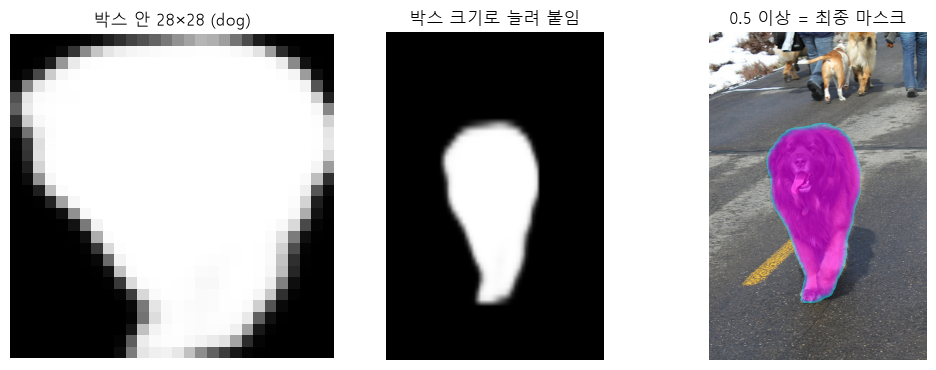

In [18]:
# 안을 열어 보기: roi_heads의 마스크 헤드 출력 = 박스마다 클래스 수 × 28 × 28
parts = [n for n, _ in mrcnn.roi_heads.named_children()]      # roi_heads 안 층 이름
print("박스 가지:", parts[:3])                                # 자르기 · 머리 · 예측
print("마스크 가지:", parts[3:])                              # 같은 3단 구조
seen = {}                                                     # 훅이 담을 곳
hook = mrcnn.roi_heads.mask_predictor.register_forward_hook(  # 마스크 헤드 출력 가로채기
    lambda mod, inp, out: seen.update(logits=out.detach()))   # 출력 저장
with torch.no_grad():                                         # 다시 추론
    mrcnn([inst_x])                                           # 같은 사진
hook.remove()                                                 # 훅 제거
print("마스크 헤드 출력:", tuple(seen["logits"].shape),       # 클래스마다 28×28
      "← 개체 × 클래스 자리 91 × 28 × 28")
print("돌려받는 masks:", tuple(mr_out["masks"].shape),        # 붙인 결과
      "← 고른 클래스 하나 · 사진 크기")

k0 = int(mr_out["labels"][0])                                      # 0번 개체가 고른 클래스
small = seen["logits"][0, k0].sigmoid()                            # 그 클래스의 28×28 확률
fig, ax = plt.subplots(1, 3, figsize=(10, 3.8))                    # 28×28 · 붙인 확률 · 최종
ax[0].imshow(small, cmap="gray", vmin=0, vmax=1)                   # ① ② 박스 안 확률
ax[0].set_title(f"박스 안 28×28 ({coco_names[k0]})", fontsize=12)  # 제목
ax[1].imshow(prob0, cmap="gray", vmin=0, vmax=1)                   # ③ 박스 크기로 늘려 붙임
ax[1].set_title("박스 크기로 늘려 붙임", fontsize=12)              # 제목
ax[2].imshow(inst_photo)                                           # 사진 위에
ax[2].imshow(np.ma.masked_where(prob0 < 0.5, prob0), cmap="cool", alpha=0.6)  # 0.5 이상만
ax[2].set_title("0.5 이상 = 최종 마스크", fontsize=12)             # 제목
for a in ax:                                                       # 축 지우기
    a.axis("off")                                                  # 눈금 없음
plt.tight_layout()                                                 # 여백
plt.show()                                                         # 표시

**결과** · 예측 정답은 91 — 배경 1 + COCO 클래스 80 + 빈 번호 10

- `박스 가지: ['box_roi_pool', 'box_head', 'box_predictor']` — 박스를 자르고 분류 · 다듬기
- `마스크 가지: ['mask_roi_pool', 'mask_head', 'mask_predictor']` — 같은 구조로 마스크
- `마스크 헤드 출력: (21, 91, 28, 28) ← 개체 × 클래스 자리 91 × 28 × 28` — 원본과 같은 모양
- `돌려받는 masks: (21, 1, 500, 333) ← 고른 클래스 하나 · 사진 크기` — 붙인 결과
- 그림: 28×28 흐린 개 모양 → 박스 자리에 늘려 붙임 → 0.5 이상만 칠함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">RoIPool</td>
<td style="text-align: left;">좌표 반올림 · 최댓값</td>
<td style="text-align: left;">박스 분류</td>
</tr>
<tr>
<td style="text-align: left;">RoIAlign</td>
<td style="text-align: left;">반올림 없이 bilinear</td>
<td style="text-align: left;">마스크 (파일별 1 · 6-1에서 손계산 13.5)</td>
</tr>
<tr>
<td style="text-align: left;">마스크 헤드</td>
<td style="text-align: left;">클래스마다 28×28 · sigmoid</td>
<td style="text-align: left;">고른 클래스만 사용</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 훅은 쓰고 나서 `remove()` (남겨 두면 매번 실행됨)

> ✅ **한 줄 정리** · Mask R-CNN은 RoIAlign으로 자른 박스 특징에서 클래스마다 28×28 마스크를 그리고, 고른 클래스 한 장을 박스 크기로 늘려 붙인다.

**딥러닝 코드에서는**

- `register_forward_hook`은 중간 층 출력을 볼 때 두루 씀 (특징 맵 시각화 등)

### 5-4. `B` 학습 손실 5개 · `model.train()` · `targets` <sub>Day02 In[34]</sub>

> 🎯 **Mask R-CNN을 학습 모드로 부르면 무엇을 돌려주는가?**

💡 **쉽게 말하면**

- 정답(박스 · 클래스 · 마스크)을 같이 주면 **손실 dict**.
- Faster R-CNN 손실 4개 + **마스크 손실 1개**.

**실행 흐름**

1. 개 한 마리 정답 만들기
2. train() 모드로 부르기
3. 손실 이름 · 값

**먼저 예측** · 손실 키는 몇 개일까? — 답은 코드 실행 결과 아래에

In [19]:
# 학습 모드: 정답(박스 · 클래스 · 마스크)을 주면 손실 5개를 dict로 돌려줌 (가중치는 안 바꿈)
one_photo, one_t = load_pair("saint_bernard_146", three=False)  # 개 한 마리 사진
one_mask = torch.tensor(one_t == 1)                             # 동물 픽셀
ys, xs = torch.nonzero(one_mask, as_tuple=True)                 # 마스크 좌표
box = [xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]          # 마스크를 감싸는 박스
target = {"boxes": torch.tensor([box], dtype=torch.float32),    # 개체마다 박스
          "labels": torch.tensor([coco_names.index("dog")]),    # 개체마다 클래스
          "masks": one_mask[None].to(torch.uint8)}              # (개체 수, H, W)
torch.manual_seed(SEED)                                         # 학습 모드 후보 뽑기 고정
mrcnn.train()                                                   # 학습 모드
losses = mrcnn([torch.tensor(one_photo).permute(2, 0, 1).float() / 255], [target])  # 손실 dict
mrcnn.eval()                                                    # 다시 평가 모드
for k, v in losses.items():                                     # 이름 · 값
    print(f"{k:17} {v.item():.3f}")                             # 분류 · 박스 · 마스크 · RPN 2개

loss_classifier   0.009
loss_box_reg      0.017
loss_mask         0.165
loss_objectness   0.001
loss_rpn_box_reg  0.002


**결과** · 예측 정답은 5개 — 분류 · 박스 · 마스크 · RPN 2개

- `loss_classifier   0.009` — 원본 0.010 (후보 박스 뽑기에 따라 조금 다름)
- `loss_mask         0.165` — 원본과 같은 값 · 마스크 이진 CE
- `loss_rpn_box_reg  0.002` — RPN 후보 박스 다듬기

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">semantic 정답</td>
<td style="text-align: left;">사진마다 지도 한 장</td>
<td style="text-align: left;">U-Net · FCN</td>
</tr>
<tr>
<td style="text-align: left;">instance 정답</td>
<td style="text-align: left;">개체마다 박스 · 클래스 · 마스크</td>
<td style="text-align: left;">Mask R-CNN</td>
</tr>
<tr>
<td style="text-align: left;">전체 손실</td>
<td style="text-align: left;">다섯 개를 더해 backward</td>
<td style="text-align: left;"><code>sum(losses.values())</code></td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 학습 모드는 정답이 없으면 에러 · 추론 뒤에는 꼭 `eval()`로 되돌리기

> ✅ **한 줄 정리** · Mask R-CNN은 학습 모드에서 Faster R-CNN 손실 4개에 마스크 손실을 더한 5개 손실을 돌려준다.

**딥러닝 코드에서는**

- `loss = sum(model(imgs, targets).values())` → `loss.backward()`

---
## 6. 세 가지 분할과 미션 파일 준비

> **이 장의 흐름**
>
> - 같은 출력도 칠하는 방식에 따라 semantic · instance · panoptic
> - 미션 다섯 질문: ① 정답 ② 번호 ③ 겹침 ④ 나누기 ⑤ 평가

<img src="images/sf2_mission.png" alt="미션 파일 다섯 질문과 확인할 것" width="763">

**파이프라인 위치** · ① 정답 형식 → 데이터 나누기 → ⑥ 평가

### 6-1. `A` semantic · instance · panoptic · `things` · `stuff` <sub>Day02 In[35] · 정리 표</sub>

> 🎯 **같은 Mask R-CNN 출력을 세 방식으로 칠하면 무엇이 다른가?**

💡 **쉽게 말하면**

- semantic은 **클래스마다 한 색**, instance는 **개체마다 다른 색 · 배경 없음**.
- panoptic은 **배경(stuff) + 개체마다 다른 색(things)**.

**실행 흐름**

1. 점수 0.8 이상 개체
2. 클래스 색 · 개체 색 · 배경 + 개체 색으로 칠하기

**먼저 예측** · semantic 그림에서 개 네 마리는 몇 가지 색일까? — 답은 코드 실행 결과 아래에

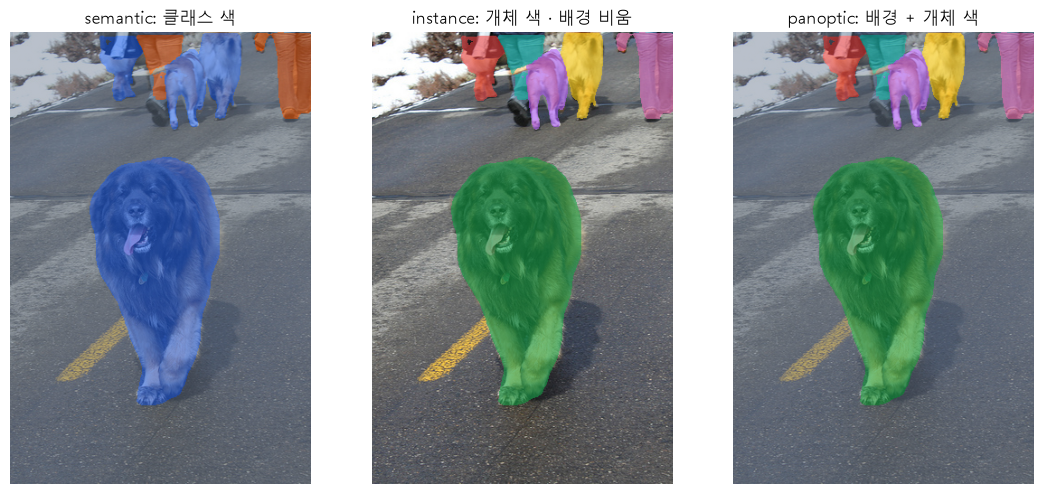

점수 0.8 이상 6개: dog, person, dog, person, dog, dog


In [20]:
# 같은 Mask R-CNN 출력을 semantic · instance · panoptic으로 칠하기
import matplotlib  # 색 변환

sure = torch.nonzero(mr_out["scores"] >= 0.8).flatten().tolist()                # 점수 0.8 이상 개체
H, W = inst_photo.shape[:2]                                                     # 사진 크기
cls_color = {"dog": "#2563eb", "person": "#ea580c"}  # semantic: 클래스마다 한 색
palette = ["#16a34a", "#f472b6", "#facc15", "#14b8a6", "#a855f7", "#ef4444"]    # 개체마다 다른 색
views = [np.zeros((H, W, 4)) for _ in range(3)]  # semantic · instance · panoptic
views[0][:] = views[2][:] = matplotlib.colors.to_rgba("#64748b", 0.45)          # 배경(stuff) = 회색
for j, i in enumerate(sure):                                                    # 개체마다
    m = (mr_out["masks"][i, 0] >= 0.5).numpy()                                  # 0.5 이상 마스크
    name = coco_names[mr_out["labels"][i]]                                      # 클래스 이름
    views[0][m] = matplotlib.colors.to_rgba(cls_color.get(name, "white"), 0.6)  # 클래스 색
    views[1][m] = views[2][m] = matplotlib.colors.to_rgba(palette[j % 6], 0.6)  # 개체 색
fig, ax = plt.subplots(1, 3, figsize=(11, 5))                                   # 세 방식
titles = ["semantic: 클래스 색", "instance: 개체 색 · 배경 비움",               # 제목
          "panoptic: 배경 + 개체 색"]
for a, v, t in zip(ax, views, titles):                                          # 세 칸
    a.imshow(inst_photo)                                                        # 사진
    a.imshow(v)                                                                 # 덮어 칠함
    a.set_title(t, fontsize=12)                                                 # 제목
    a.axis("off")                                                               # 눈금 없음
plt.tight_layout()                                                              # 여백
plt.show()                                                                      # 표시
kept = ", ".join(coco_names[mr_out["labels"][i]] for i in sure)                 # 이름 목록
print(f"점수 0.8 이상 {len(sure)}개:", kept)                                    # 개체 목록

**결과** · 예측 정답은 한 가지 — 같은 클래스 = 같은 색

- 그림: semantic은 개가 모두 파랑 · instance는 개체마다 다른 색 · panoptic은 회색 배경 + 개체 색
- `점수 0.8 이상 6개: dog, person, dog, person, dog, dog` — 원본과 같은 개체

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">semantic</td>
<td style="text-align: left;">모든 픽셀에 클래스 · 개체 구분 없음</td>
<td style="text-align: left;">Day1 · 미션 · 평가 mIoU</td>
</tr>
<tr>
<td style="text-align: left;">instance</td>
<td style="text-align: left;">things만 · 개체마다 마스크</td>
<td style="text-align: left;">Mask R-CNN · 평가 Mask AP</td>
</tr>
<tr>
<td style="text-align: left;">panoptic</td>
<td style="text-align: left;">모든 픽셀에 클래스 + things는 개체 번호</td>
<td style="text-align: left;">평가 PQ (이름만)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 미션 COCO 파일은 개체마다 polygon이 있지만, 과제는 클래스 지도 → 개체 번호는 버림

> ✅ **한 줄 정리** · semantic은 클래스 지도, instance는 개체 마스크 목록, panoptic은 배경까지 포함해 모든 픽셀에 클래스와 개체 번호를 준다.

**딥러닝 코드에서는**

- things = 셀 수 있는 것(개 · 사람 · 공) · stuff = 셀 수 없는 것(도로 · 하늘 · 잔디)

### 6-2. `A` ③ 겹침: 칠하는 순서 · `ImageDraw.polygon` · `덮어쓰기` <sub>Day02 In[45] · In[46] · In[17] (원본: 미션 Frame 53)</sub>

> 🎯 **polygon을 json 순서대로 한 지도에 덮어 칠하면 작은 공은 남는가?**

💡 **쉽게 말하면**

- 겹친 픽셀은 **나중에 칠한 클래스**가 차지.
- 넓은 잔디를 마지막에 칠하면 **공 · 선수가 지워짐**.

**실행 흐름**

1. 선수 · 공 · 잔디 polygon (json 순서라고 가정)
2. 자기 polygon 픽셀
3. 순서 두 가지로 칠해 남은 픽셀 비교

**먼저 예측** · json 순서(잔디 마지막)로 칠하면 공 픽셀은 몇 개 남을까? — 답은 코드 실행 결과 아래에

In [21]:
# 미션 ③ 한 픽셀에 답이 둘이면: polygon을 json 순서대로 덮어 칠하면 작은 공이 사라짐 (직접 만든 예)
anns = [("Team A", [(150, 80), (190, 80), (190, 200), (150, 200)]),  # (클래스, polygon) · json 순서
        ("Ball", [(196, 186), (206, 186), (206, 196), (196, 196)]),  # 선수 발밑의 작은 공
        ("Ground", [(0, 120), (400, 120), (400, 240), (0, 240)])]    # 넓은 잔디 (마지막)
own = {}  # annotation마다 자기 polygon만 칠한 지도
for k, (name, poly) in enumerate(anns):                              # 하나씩
    m = Image.new("L", (400, 240), 0)                                # 빈 지도
    ImageDraw.Draw(m).polygon(poly, fill=1)                          # polygon 안 = 1
    own[k] = np.array(m, dtype=bool)                                 # True/False 지도


def paint_order(order):            # 주어진 순서로 덮어 칠한 뒤 남은 픽셀 수
    lab = np.full((240, 400), -1)  # -1 = 안 칠함
    for k in order:                # 뒤에 칠한 것이 위
        lab[own[k]] = k            # 덮어쓰기
    return [int((lab == k).sum()) for k in range(len(anns))]  # annotation별 남은 픽셀


print("자기 polygon 픽셀  :", [int(own[k].sum()) for k in range(3)])  # 원래 넓이
print("json 순서로 칠함   :", paint_order([0, 1, 2]))    # 잔디가 마지막 → 공 · 발 사라짐
print("잔디 먼저 · 공 마지막:", paint_order([2, 0, 1]))  # 작은 것을 위로

자기 polygon 픽셀  : [4961, 121, 48000]
json 순서로 칠함   : [1640, 0, 48000]
잔디 먼저 · 공 마지막: [4961, 121, 44558]


**결과** · 예측 정답은 0개 — 공이 정답에서 사라짐

- `자기 polygon 픽셀  : [4961, 121, 48000]` — 선수 · 공 · 잔디
- `json 순서로 칠함   : [1640, 0, 48000]` — 원본 Frame 53도 공 · 선수가 모두 0으로
- `잔디 먼저 · 공 마지막: [4961, 121, 44558]` — 작은 것을 위로 칠하면 모두 남음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 무엇이 정답인가</td>
<td style="text-align: left;">파일 이름이 아니라 값 · 출처 (<code>___save</code> 45색은 아님 · <code>___fuse</code> 11색)</td>
<td style="text-align: left;">열어서 색 수 세기</td>
</tr>
<tr>
<td style="text-align: left;">② 어떤 번호</td>
<td style="text-align: left;">category id(1392794 등) → 0부터 번호표</td>
<td style="text-align: left;">정답 0개 클래스(Coaches)도 표에</td>
</tr>
<tr>
<td style="text-align: left;">③ 겹침</td>
<td style="text-align: left;">칠하는 순서 = 정답 규칙</td>
<td style="text-align: left;">후보 규칙 둘 이상 · 작은 객체가 남는지 비교</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `___fuse.png`는 이미 선수 · 공이 위 · 색 → 이름 표는 직접 만들어야 함
> - Team B와 Goalkeeper B는 거의 같은 색 → bilinear · jpg 저장 금지

> ✅ **한 줄 정리** · COCO polygon으로 정답 지도를 만들 때는 칠하는 순서가 곧 정답 규칙이며, 작은 객체가 남는 순서를 직접 정해야 한다.

**딥러닝 코드에서는**

- 빈 지도는 번호표에 없는 값(255)으로 시작 — 0이 클래스면 '안 칠한 곳 = 그 클래스'가 됨

### 6-3. `A` ④ 나누기 · ⑤ 평가 · `hashlib.md5` · `assert` <sub>Day02 In[48] ~ In[50] · ⑤ 평가 (원본: 미션 Frame 14 = Frame 71)</sub>

> 🎯 **내용이 같은 사진이 train과 test에 갈라지지 않게 하려면 어떻게 나누는가?**

💡 **쉽게 말하면**

- 파일 내용의 **지문**(md5)이 같으면 같은 사진.
- 같은 지문끼리 **묶음**을 만들고 묶음 단위로 나눔.

**실행 흐름**

1. 14장 중 내용이 같은 것끼리 묶기
2. 묶음 단위로 섞어 test 2묶음
3. assert로 겹침 0 확인

**먼저 예측** · 14개 파일은 몇 묶음이 될까? — 답은 코드 실행 결과 아래에

In [22]:
# 미션 ④ 어느 사진끼리 나누나: 내용이 같은 파일을 묶고 묶음 단위로 train / test (직접 만든 예)
import hashlib  # 파일 내용 지문

files = {f"Frame ({i})": bytes([i % 7]) * 64 for i in range(1, 15)}           # 14장 · 내용 7가지
groups = {}                                                                   # 지문 → 파일 이름들
for name, raw in files.items():                                               # 파일마다
    groups.setdefault(hashlib.md5(raw).hexdigest(), []).append(name)          # 같은 내용끼리 모음
bundles = sorted(groups.values())                                             # 묶음 목록
print("파일", len(files), "개 → 묶음", len(bundles), "개 · 예:", bundles[0])  # 같은 사진 묶음
rng = random.Random(SEED)                                                     # 나누기 고정
rng.shuffle(bundles)                                                          # 묶음 단위로 섞기
test_ids = [n for b in bundles[:2] for n in b]                                # 묶음 2개 = test
train_ids = [n for b in bundles[2:] for n in b]                               # 나머지 = train
digest = {n: hashlib.md5(raw).hexdigest() for n, raw in files.items()}        # 파일마다 지문
same = {digest[n] for n in train_ids} & {digest[n] for n in test_ids}         # 양쪽에 다 있는 지문
assert not same, "train과 test에 같은 사진이 있음"                            # 새는 사진 없음 확인
print("train", len(train_ids), "장 · test", len(test_ids),                    # 결과
      "장 · 겹치는 내용 0 (assert 통과)")

파일 14 개 → 묶음 7 개 · 예: ['Frame (1)', 'Frame (8)']
train 10 장 · test 4 장 · 겹치는 내용 0 (assert 통과)


**결과** · 예측 정답은 7묶음 — 내용이 7가지뿐 (번호가 멀리 떨어진 같은 사진)

- `파일 14 개 → 묶음 7 개 · 예: ['Frame (1)', 'Frame (8)']` — 원본 미션: Frame 14 = Frame 71
- `train 10 장 · test 4 장 · 겹치는 내용 0 (assert 통과)` — 묶음 단위라 새는 사진 없음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">④ 사진 단위로 무작위</td>
<td style="text-align: left;">같은 장면이 양쪽에 → 점수가 부풀음</td>
<td style="text-align: left;">쓰지 않음</td>
</tr>
<tr>
<td style="text-align: left;">④ 묶음 단위</td>
<td style="text-align: left;">같은 파일 · 같은 장면을 한쪽에만</td>
<td style="text-align: left;">하이라이트 영상 (다시보기)</td>
</tr>
<tr>
<td style="text-align: left;">⑤ 평가</td>
<td style="text-align: left;">손실 ≠ 지표 · 어떤 mIoU인지 · test는 한 번</td>
<td style="text-align: left;">val은 train 안에서 따로</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - ⑤ 보고 문장: 평균에 넣은 클래스 · 정답 0개 클래스 · ignore 처리 · 모아서/사진마다 · test 본 횟수

> ✅ **한 줄 정리** · 같은 사진이 train과 test에 갈라지지 않게 내용 지문으로 묶어 묶음 단위로 나누고, 평가 방식은 보고 문장에 모두 적는다.

**딥러닝 코드에서는**

- `assert not (set(train) & set(test))` — 나눈 직후 한 줄로 확인

---
## 7. 종합 실습 · 100장: 처음부터 vs ImageNet 인코더

> **이 장의 흐름**
>
> - 원본 '데이터가 100장뿐이면' · 1 ~ 4장을 한 번에 사용
> - 구조 · 데이터 · epoch · lr · seed는 같게, 시작 가중치 하나만 다르게

<img src="images/sf2_practice.png" alt="바꾼 것 하나: 시작 가중치 (무작위 vs ImageNet)" width="763">

**파이프라인 위치** · ① 데이터 → ② 모델 → ④ 학습 → ⑥ 평가

> 🎯 **100장 · 40 epoch에서 처음부터 학습한 U-Net과 ImageNet ResNet18 인코더 U-Net의 클래스별 IoU는?**

💡 **쉽게 말하면**

- 사진 100장으로 **처음부터 배우기** vs **이미 사진을 많이 본 눈으로 시작하기**.
- 나머지 조건은 모두 같게 두고 **하나만** 바꿈.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 문법</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">품종 37개가 모두 들어간 100장 고르기</td>
<td style="text-align: left;">1-1 정답</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">같은 ResUNet · 40 epoch · lr 0.001 · seed 42, 시작 가중치만 다르게</td>
<td style="text-align: left;">1-2 · 1-3</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">val 손실 최저 epoch를 best로 저장 → 다시 불러와 평가</td>
<td style="text-align: left;">1-3 · 1-4</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">클래스별 IoU · 예측 그림</td>
<td style="text-align: left;">3 · 4장</td>
</tr>
</tbody>
</table>

**먼저 예측** · 두 모델의 차이가 가장 큰 클래스는? — 답은 코드 실행 결과 아래에

In [23]:
# 1단계: 학습 사진 100장 고르기 (품종 37개가 모두 들어가게) · 나머지 조건 고정
by_breed = {}                                                               # 품종 → 사진 이름들
for n in TRAIN:                                                             # 학습 후보
    by_breed.setdefault(n.rsplit("_", 1)[0], []).append(n)                  # 이름 앞부분 = 품종
rng = random.Random(SEED)                                                   # 고르기 고정
ids100 = [rng.choice(v) for v in by_breed.values()]                         # 품종마다 1장 (37장)
rest = [n for n in TRAIN if n not in set(ids100)]                           # 남은 사진
ids100 += rng.sample(rest, 100 - len(ids100))                               # 63장 더 → 100장
X100, Y100 = load_set(ids100)                                               # 128×128 텐서
cats = sum(SPECIES[n] == 1 for n in ids100)                                 # 고양이 수
print(f"100장 · 품종 {len(by_breed)}개 · 고양이 {cats} · 개 {100 - cats}",  # 확인
      f"· 입력 {tuple(X100.shape)}")

100장 · 품종 37개 · 고양이 39 · 개 61 · 입력 (100, 3, 128, 128)


In [24]:
# 2단계: 같은 구조 · 같은 조건 · 시작 가중치만 다르게 (처음부터 vs ImageNet) · 40 epoch
runs = {}                                                             # 결과 모음
for run, pre in [("S100 처음부터", False), ("P100 ImageNet", True)]:  # 바꾸는 것은 하나
    torch.manual_seed(SEED)                                           # 디코더 초기값 같게
    model = ResUNet(3, pretrained=pre).to(device)                     # 구조는 같음
    best, hist = train(model, X100, Y100, epochs=40, Xv=Xva, Yv=Yva)  # val 손실 최저 = best
    runs[run] = (model, best, hist)                                   # 저장
    print(f"{run} · best epoch {hist.index(min(hist)) + 1} · val 손실 {min(hist):.3f}")  # 기록

S100 처음부터 · best epoch 6 · val 손실 0.699


P100 ImageNet · best epoch 12 · val 손실 0.428


In [25]:
# 3단계: best를 다시 불러와 평가 (저장만 하고 끝내지 않기) · 클래스별 IoU
print("              | 배경   | 고양이 | 개     | mIoU")   # 머리
for run, (model, best, hist) in runs.items():              # 두 모델
    model.load_state_dict(best)                            # best 가중치로 덮어씀
    pred, cm, _ = evaluate(model, Xva, Yva)                # 검증 460장
    inter = cm.diag().float()                              # TP
    iou = inter / (cm.sum(0) + cm.sum(1) - inter).float()  # 클래스별 IoU
    runs[run] = (model, pred, iou)                         # 그림용으로 예측 보관
    print(f"{run} | " + " | ".join(f"{v:.3f}" for v in iou) + f" | {iou.mean():.3f}")  # 한 줄

              | 배경   | 고양이 | 개     | mIoU


S100 처음부터 | 0.725 | 0.006 | 0.401 | 0.377


P100 ImageNet | 0.882 | 0.454 | 0.605 | 0.647


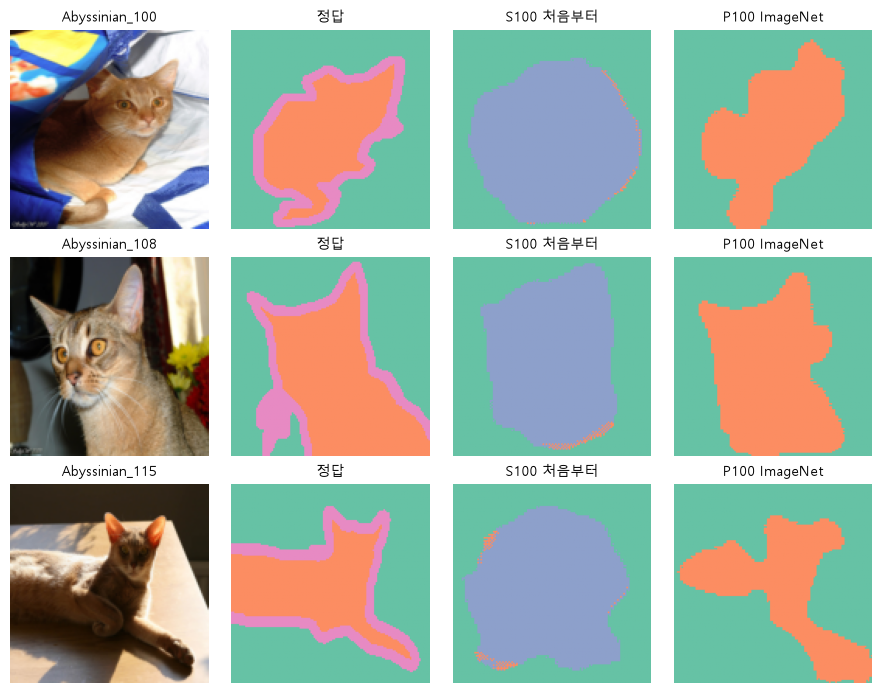

In [26]:
# 4단계: 같은 검증 사진 3장의 정답 · 두 모델 예측
show = [0, 1, 2]                                                       # 검증 앞 3장
fig, ax = plt.subplots(3, 4, figsize=(9, 7))                           # 사진 · 정답 · 모델 2개
for r, j in enumerate(show):                                           # 한 줄에 한 장
    gt = torch.where(Yva[j] == IGNORE, 3, Yva[j])                      # 정답 (경계 = 3)
    panels = [(load_pair(VAL[j], 128)[0], VAL[j][:16]), (gt, "정답")]  # 사진 · 정답
    panels += [(runs[k][1][j], k) for k in runs]                       # 두 모델 예측
    for c, (img, title) in enumerate(panels):                          # 4칸
        ax[r, c].imshow(img, cmap=None if c == 0 else "Set2", vmin=0, vmax=7)  # 번호별 색
        ax[r, c].set_title(title, fontsize=10)                         # 제목
        ax[r, c].axis("off")                                           # 눈금 없음
plt.tight_layout()                                                     # 여백
plt.show()                                                             # 표시

**결과** · 예측 정답은 고양이 — 0.006 → 0.454 (처음부터 모델은 고양이를 거의 못 칠함)

- `S100 처음부터 · best epoch 6 · val 손실 0.699` — 원본 best epoch 25 · 0.657
- `P100 ImageNet · best epoch 12 · val 손실 0.428` — 원본 20 · 0.401
- `S100 처음부터 | 0.725 | 0.006 | 0.401 | 0.377` — 원본 0.765 · 0.004 · 0.403 · 0.390
- `P100 ImageNet | 0.882 | 0.454 | 0.605 | 0.647` — 원본 0.907 · 0.088 · 0.555 · 0.517 · mIoU +0.27
- 그림 색은 4-1과 같음 · 처음부터 모델은 고양이를 개 · 배경으로 칠함 · ImageNet 모델은 모양과 종이 더 맞음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">RUN_S100 (처음부터)</td>
<td style="text-align: left;">모든 가중치를 100장으로 배움</td>
<td style="text-align: left;">데이터가 충분할 때</td>
</tr>
<tr>
<td style="text-align: left;">RUN_P100 (ImageNet)</td>
<td style="text-align: left;">인코더가 이미 배운 특징에서 시작 · 같이 학습</td>
<td style="text-align: left;">데이터가 적을 때 먼저 시도</td>
</tr>
<tr>
<td style="text-align: left;">best 다시 불러오기</td>
<td style="text-align: left;">저장한 가중치로 평가해 기록과 맞는지</td>
<td style="text-align: left;">저장만 하고 끝내지 않기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 말할 수 있는 것: 이 조건(seed 하나 · 이 100장 · 40 epoch)에서 이만큼 달랐음
> - 말할 수 없는 것: '100장이면 언제나 ImageNet이 낫다' — seed · 사진을 바꿔 여러 번 봐야 함

> ✅ **한 줄 정리** · 데이터가 적을 때 ImageNet 인코더로 시작하면 같은 조건에서 IoU가 크게 오르지만, 결론은 그 조건 안에서만 말한다.

**딥러닝 코드에서는**

- 미션 실험 기록 한 줄: 무엇을 바꿨나 · 나머지는 같게 뒀나 · best를 무엇으로 골랐나 · 다시 불러와 평가했나

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 3클래스</td>
<td style="text-align: left;">정답 번호 · 출력 채널만 바뀜 · 고양이 IoU 0.456 · 고양이 → 개 0.425</td>
<td style="text-align: left;">1-1 ~ 1-4</td>
</tr>
<tr>
<td style="text-align: left;">2. 증강</td>
<td style="text-align: left;">사진만 뒤집으면 IoU 0.43 · Image + Mask · 빈 자리 255 · 자르면 공 32%만 남음</td>
<td style="text-align: left;">2-1 ~ 2-4</td>
</tr>
<tr>
<td style="text-align: left;">3. 작은 클래스</td>
<td style="text-align: left;">A(놓침) CE 0.071 &lt; C 0.313 · Dice 0.001 vs 0.309 · soft Dice</td>
<td style="text-align: left;">3-1 ~ 3-4</td>
</tr>
<tr>
<td style="text-align: left;">4. 오류 분석</td>
<td style="text-align: left;">종 틀림 50% 초과 72장 · 관찰 / 후보 원인 / 확인 방법</td>
<td style="text-align: left;">4-1</td>
</tr>
<tr>
<td style="text-align: left;">5 · 6. instance · 미션</td>
<td style="text-align: left;">덩어리 1 vs 개체 8 · 28×28 · 칠하는 순서 · 묶음 나누기</td>
<td style="text-align: left;">5 · 6장</td>
</tr>
<tr>
<td style="text-align: left;">7. 100장 실험</td>
<td style="text-align: left;">mIoU 처음부터 0.377 vs ImageNet 0.647 · 고양이 0.006 vs 0.454</td>
<td style="text-align: left;">7. 종합 실습</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">3클래스</td>
<td style="text-align: left;">정답 번호 · 출력 채널만</td>
<td style="text-align: left;"><code>Conv2d(64, C, 1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">혼동 행렬</td>
<td style="text-align: left;">행 정답 · 열 예측 · 픽셀 단위</td>
<td style="text-align: left;"><code>bincount(y * C + p)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">증강</td>
<td style="text-align: left;">자리 변환은 함께 · Mask · 빈 자리 255</td>
<td style="text-align: left;"><code>tv_tensors.Mask</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">작은 클래스</td>
<td style="text-align: left;">CE 평균에 묻힘 · Dice가 드러냄</td>
<td style="text-align: left;">soft Dice 손실</td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">IoU · Dice</td>
<td style="text-align: left;">Dice = 2·IoU ÷ (1 + IoU)</td>
<td style="text-align: left;">지표 보고</td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">오류 분석</td>
<td style="text-align: left;">IoU → 혼동 행렬 → 사진 → 관찰/원인</td>
<td style="text-align: left;">미션 보고서</td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">Mask R-CNN</td>
<td style="text-align: left;">탐지 점수 · 마스크 확률 · 28×28</td>
<td style="text-align: left;">개체 수 세기</td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">미션 준비</td>
<td style="text-align: left;">정답 · 번호 · 겹침 · 나누기 · 평가</td>
<td style="text-align: left;">학습 전 점검</td>
</tr>
<tr>
<td style="text-align: left;"><code>B</code></td>
<td style="text-align: left;">사전학습 인코더</td>
<td style="text-align: left;">적은 데이터에서 시작점</td>
<td style="text-align: left;">fine-tune</td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">클래스가 3개가 되면 코드에서 바뀌는 두 가지는?</td>
</tr>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">혼동 행렬의 행과 열은?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">사진만 뒤집으면 에러가 나는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">v2에서 정답을 함께 바꾸려면?</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">회전의 빈 자리를 정답에서 무엇으로 채우나?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">물체를 놓친 A의 CE 평균이 작은 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">IoU 0.29의 Dice는?</td>
</tr>
<tr>
<td style="text-align: left;">3-4</td>
<td style="text-align: left;">지표 Dice를 손실로 못 쓰는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">두 기준은 각각 무엇을 고르는가?</td>
</tr>
<tr>
<td style="text-align: left;">5-3</td>
<td style="text-align: left;">마스크 헤드 출력 모양은?</td>
</tr>
<tr>
<td style="text-align: left;">6-2</td>
<td style="text-align: left;">polygon을 json 순서로 칠할 때 위험은?</td>
</tr>
<tr>
<td style="text-align: left;">6-3</td>
<td style="text-align: left;">같은 사진이 train · test에 갈라지지 않게 하려면?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 정답 `torch.tensor([[0, 1], [255, 2]])`에서 255를 뺀 클래스별 픽셀 수를 `bincount`로 출력
2. TP 6 · FP 2 · FN 2일 때 IoU와 Dice를 소수 둘째 자리로 출력
3. 점수 `torch.tensor([0.95, 0.4, 0.7])`에서 0.5 이상인 개체 수를 출력

In [27]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 2-3에서 회전 각도를 45도로 바꾸면 '채움 255'의 배경 비율은 0.56보다 커질까 작아질까?
2. 3-2에서 물체를 5×5(25픽셀)로 키우면 A의 CE 평균은 어떻게 될까?
3. 6-2에서 순서를 [0, 2, 1](선수 → 잔디 → 공)로 바꾸면 남는 픽셀은?

In [28]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">정답 번호 · 마지막 출력 채널</td>
</tr>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">행 = 정답 · 열 = 예측 · 단위는 픽셀</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">안 남 · IoU로만 드러남 (0.43)</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;"><code>tv_tensors.Mask</code>로 감싸기</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">255 (손실 · 평가에서 뺌)</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">9픽셀 손실이 1,015픽셀 평균에 묻힘</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">0.44</td>
</tr>
<tr>
<td style="text-align: left;">3-4</td>
<td style="text-align: left;">argmax가 기울기를 끊음 → soft Dice</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">탐지 점수 = 개체 · 마스크 확률 = 픽셀</td>
</tr>
<tr>
<td style="text-align: left;">5-3</td>
<td style="text-align: left;">(개체, 91, 28, 28)</td>
</tr>
<tr>
<td style="text-align: left;">6-2</td>
<td style="text-align: left;">넓은 클래스가 작은 공 · 선수를 덮음</td>
</tr>
<tr>
<td style="text-align: left;">6-3</td>
<td style="text-align: left;">내용 지문으로 묶어 묶음 단위로 나누기</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
y = torch.tensor([[0, 1], [255, 2]])
print(torch.bincount(y[y != 255], minlength=3).tolist())  # [1, 1, 1]
TP, FP, FN = 6, 2, 2
print(f"{TP / (TP + FP + FN):.2f} {2 * TP / (2 * TP + FP + FN):.2f}")  # 0.60 0.75
print(int((torch.tensor([0.95, 0.4, 0.7]) >= 0.5).sum()))  # 2
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">작아짐 — 빈 모서리가 넓어져 255가 더 많아짐 (직접 실행해 확인)</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">커짐 — 8 × 25 ÷ 1024 ≈ 0.20 (물체 픽셀 비율만큼)</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">[1640, 121, 44558] 근처 — 공은 남고 선수 발 아래는 잔디가 덮음 (직접 실행해 확인)</td>
</tr>
</tbody>
</table>

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 사진만 뒤집어도 에러가 없으니 증강이 맞다고 판단</td>
<td style="text-align: left;">에러가 없으면 맞다고 봄</td>
<td style="text-align: left;">겹쳐 그리기 · IoU로 확인</td>
<td style="text-align: left;">정답도 같은 변환을 받았나?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. 분할 데이터 증강에서 주의할 점은?**
> - 뒤집기 · 회전 · 자르기처럼 자리를 바꾸는 변환은 정답 지도에도 똑같이 적용해야 하고, 정답은 번호라 nearest로 다뤄야 합니다.
> - 회전으로 생긴 빈 자리는 255로 채워 손실에서 빼고, 무작위 자르기는 작은 클래스가 남는지 확인합니다.

**Q2. 작은 클래스를 잘 못 찾을 때 무엇부터 보나요?**
> - 먼저 정답에 그 클래스가 실제로 남아 있는지 봅니다.
> - polygon을 칠하는 순서나 자르기 때문에 사라질 수 있기 때문입니다.
> - 그다음 픽셀 비율을 보고, CE 평균에 묻히는 것이 원인이면 Dice 손실이나 클래스 가중치를 비교 실험합니다.

**Q3. Dice를 손실로 쓸 때 soft Dice를 쓰는 이유는?**
> - argmax로 0/1을 만든 Dice는 기울기가 끊겨 학습에 쓸 수 없습니다.
> - 확률을 그대로 넣어 계산한 soft Dice는 미분이 가능해 손실로 쓸 수 있습니다.

**Q4. Mask R-CNN의 두 기준은 무엇인가요?**
> - 탐지 점수 기준은 어느 개체를 남길지를 박스 단위로 정하고, 마스크 확률 기준은 남긴 개체의 어느 픽셀을 칠할지를 픽셀 단위로 정합니다.
> - 효과를 보려면 한 번에 하나만 바꿉니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>OxfordIIITPet</code> · trimap</td>
<td style="text-align: left;">torchvision.datasets</td>
<td style="text-align: left;">사진 + 1 · 2 · 3 정답</td>
<td style="text-align: left;">prep <code>DATA / "annotations" / "trimaps"</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>resnet18(weights=IMAGENET1K_V1)</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">사전학습 인코더</td>
<td style="text-align: left;">1-2 <code>ResUNet(3)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>F.cross_entropy(ignore_index=255)</code></td>
<td style="text-align: left;">torch.nn.functional</td>
<td style="text-align: left;">경계 뺀 픽셀 CE</td>
<td style="text-align: left;">1-3 <code>train(...)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.bincount</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">혼동 행렬 · 픽셀 수</td>
<td style="text-align: left;">1-3 <code>bincount(Y * 3 + pred)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>tv_tensors.Image</code> · <code>Mask</code></td>
<td style="text-align: left;">torchvision</td>
<td style="text-align: left;">사진 · 정답 타입</td>
<td style="text-align: left;">2-2 <code>flip(Image(img_t), Mask(mask_t))</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>v2.RandomRotation(fill=…)</code></td>
<td style="text-align: left;">torchvision.transforms.v2</td>
<td style="text-align: left;">빈 자리 값</td>
<td style="text-align: left;">2-3 <code>fill={Image: 0, Mask: 255}</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>v2.RandomCrop</code></td>
<td style="text-align: left;">torchvision.transforms.v2</td>
<td style="text-align: left;">무작위 자르기</td>
<td style="text-align: left;">2-4 <code>crop(photo_f, ball)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>softmax</code> · soft Dice</td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">미분 가능한 Dice</td>
<td style="text-align: left;">3-4 <code>1 - 2 * (p * t).sum() / ...</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>maskrcnn_resnet50_fpn</code></td>
<td style="text-align: left;">torchvision.models.detection</td>
<td style="text-align: left;">instance 분할</td>
<td style="text-align: left;">5-2 <code>mrcnn([inst_x])[0]</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>register_forward_hook</code></td>
<td style="text-align: left;">torch.nn.Module</td>
<td style="text-align: left;">중간 출력 보기</td>
<td style="text-align: left;">5-3 <code>mask_predictor.register_forward_hook</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>ImageDraw.polygon</code></td>
<td style="text-align: left;">PIL</td>
<td style="text-align: left;">polygon → 지도</td>
<td style="text-align: left;">6-2 <code>polygon(poly, fill=1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>hashlib.md5</code></td>
<td style="text-align: left;">hashlib</td>
<td style="text-align: left;">같은 파일 묶기</td>
<td style="text-align: left;">6-3 <code>md5(raw).hexdigest()</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">정답도 같은 자리 변환 (Mask)</td>
<td style="text-align: left;">사진만 뒤집기</td>
</tr>
<tr>
<td style="text-align: left;">빈 자리는 255</td>
<td style="text-align: left;">빈 자리를 0(배경)으로</td>
</tr>
<tr>
<td style="text-align: left;">클래스별 IoU · 혼동 행렬 함께</td>
<td style="text-align: left;">mIoU 하나만 보고</td>
</tr>
<tr>
<td style="text-align: left;">관찰과 후보 원인을 나눠 적기</td>
<td style="text-align: left;">원인을 하나로 단정</td>
</tr>
<tr>
<td style="text-align: left;">묶음 단위로 train / test</td>
<td style="text-align: left;">같은 사진을 양쪽에</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">2클래스 vs 3클래스</td>
<td style="text-align: left;">동물 1 vs 종 1 · 2</td>
<td style="text-align: left;">번호 · 채널만 바뀜</td>
</tr>
<tr>
<td style="text-align: left;">그냥 텐서 vs Mask</td>
<td style="text-align: left;">첫째만 변환 vs 같이 · nearest</td>
<td style="text-align: left;">Mask</td>
</tr>
<tr>
<td style="text-align: left;">채움 0 vs 255</td>
<td style="text-align: left;">가짜 배경 vs 무시</td>
<td style="text-align: left;">255</td>
</tr>
<tr>
<td style="text-align: left;">CE 평균 vs Dice</td>
<td style="text-align: left;">픽셀 평균 vs 클래스 겹침</td>
<td style="text-align: left;">작은 클래스는 Dice도</td>
</tr>
<tr>
<td style="text-align: left;">지표 Dice vs soft Dice</td>
<td style="text-align: left;">argmax vs 확률</td>
<td style="text-align: left;">손실은 soft</td>
</tr>
<tr>
<td style="text-align: left;">탐지 점수 vs 마스크 확률</td>
<td style="text-align: left;">개체 vs 픽셀</td>
<td style="text-align: left;">하나씩 바꾸기</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개 · 3-2 장난감 표를 손으로 다시</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">7장 두 모델 비교를 빈 셀에 다시 짜서 결과 비교</td>
<td style="text-align: left;">30분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 · 미션 시작 전에 6장 다섯 질문 점검</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 Day02 노트북(HTML · 코드 89칸)을 7단원 순서대로 1 ~ 6장 · 18개 섹션으로 나눔
- 원본의 공유 모듈(cv04_unet · cv04_day2) · 미리 학습한 가중치(runs/)는 없음 → 데이터 읽기 · ResUNet · 학습 · 평가를 직접 정의
- 학습이 필요한 칸(RUN_C · RUN_S100 · RUN_P100)은 사진 수 · epoch를 줄여 직접 다시 학습 → 숫자는 원본과 다름 (해설에 원본 값)
- 미션(football) 데이터가 필요한 칸은 같은 생각을 직접 만든 작은 예로 (2-4 · 6-2 · 6-3) · 미션 자체는 제외
- 원본 '데이터가 100장뿐이면'은 1 ~ 4장 내용을 다 쓰므로 7장 종합 실습으로 옮김

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
</tbody>
</table>

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">이 노트북</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">In[51] ~ In[53]</td>
<td style="text-align: left;">준비 · 클래스 셋 · 정답 번호 · 출력 채널 · CE</td>
<td style="text-align: left;">준비 · 1-1</td>
</tr>
<tr>
<td style="text-align: left;">In[54] · In[55]</td>
<td style="text-align: left;">RUN_C 평가 · 혼동 행렬</td>
<td style="text-align: left;">1-3 · 1-4</td>
</tr>
<tr>
<td style="text-align: left;">In[56] · In[57]</td>
<td style="text-align: left;">사진만 뒤집기</td>
<td style="text-align: left;">2-1</td>
</tr>
<tr>
<td style="text-align: left;">In[58] · In[59]</td>
<td style="text-align: left;">v2 · Image · Mask · 크기 조정</td>
<td style="text-align: left;">2-2</td>
</tr>
<tr>
<td style="text-align: left;">In[60] · In[61]</td>
<td style="text-align: left;">회전 빈 자리 · 색 바꾸기</td>
<td style="text-align: left;">2-3 · 2-4 비교표</td>
</tr>
<tr>
<td style="text-align: left;">In[62]</td>
<td style="text-align: left;">무작위 자르기 · 공</td>
<td style="text-align: left;">2-4</td>
</tr>
<tr>
<td style="text-align: left;">In[63] ~ In[16]</td>
<td style="text-align: left;">100장 · ResNet18 인코더 · best 다시 불러오기</td>
<td style="text-align: left;">1-2 · 7. 종합 실습</td>
</tr>
<tr>
<td style="text-align: left;">In[17] ~ In[21]</td>
<td style="text-align: left;">작은 클래스 · CE vs Dice · IoU · soft Dice</td>
<td style="text-align: left;">3-1 ~ 3-4</td>
</tr>
<tr>
<td style="text-align: left;">In[22] · In[23]</td>
<td style="text-align: left;">종을 틀린 사진 · 관찰 / 원인 표</td>
<td style="text-align: left;">4-1</td>
</tr>
<tr>
<td style="text-align: left;">In[24] ~ In[34]</td>
<td style="text-align: left;">덩어리 · Mask R-CNN · 두 기준 · 28×28 · RoIAlign · 손실</td>
<td style="text-align: left;">5-1 ~ 5-4</td>
</tr>
<tr>
<td style="text-align: left;">In[35] · 정리 표</td>
<td style="text-align: left;">semantic · instance · panoptic</td>
<td style="text-align: left;">6-1</td>
</tr>
<tr>
<td style="text-align: left;">In[36] ~ In[47]</td>
<td style="text-align: left;">미션 ① 정답 ② 번호 ③ 겹침</td>
<td style="text-align: left;">6-2</td>
</tr>
<tr>
<td style="text-align: left;">In[48] ~ In[50] · ⑤</td>
<td style="text-align: left;">미션 ④ 나누기 · ⑤ 평가</td>
<td style="text-align: left;">6-3</td>
</tr>
</tbody>
</table>

### 전체 코드

1 ~ 7장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

In [29]:
# ---------- 0. 준비 ----------
# 실행 환경 · 데이터 준비 (원본: 강의 폴더의 cv04_unet · cv04_day2 모듈 → 여기서 직접 정의)
import os      # 환경 변수
import random  # 파이썬 난수

if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복 허용
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # GPU 행렬 곱도 같은 값
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # 결정적 cuBLAS 작업 공간

from pathlib import Path  # 경로

import numpy as np               # 배열
import torch                     # 텐서 · 모델
import torch.nn.functional as F  # 손실 · 보간
import torchvision               # 데이터셋 · 모델 · 변환
from PIL import Image            # 사진 · 정답 파일 열기
from torch import nn             # 층

SEED = 42                                                              # 난수 기준값
random.seed(SEED)                                                      # 파이썬 random 고정
np.random.seed(SEED)                                                   # numpy 고정
torch.manual_seed(SEED)                                                # torch 고정
torch.backends.cudnn.deterministic = True                              # GPU 합성곱도 같은 값
torch.backends.cudnn.benchmark = False                                 # 계산 방법 고정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 있으면 GPU

DATA = Path("data") / "oxford-iiit-pet"          # 노트북 옆 data/ 폴더
if not (DATA / "images").is_dir():  # 처음 한 번만 내려받기 (약 800MB · GitHub에는 올리지 않음)
    torchvision.datasets.OxfordIIITPet("data", split="trainval",  # 사진 + trimap
                                       target_types="segmentation", download=True)  # 처음 한 번
IGNORE, CLASSES = 255, ["배경", "고양이", "개"]  # 경계(미분류)는 255 · 클래스 3개
SPECIES = {}                                     # 사진 이름 → 1 고양이 · 2 개
for line in (DATA / "annotations" / "list.txt").read_text().splitlines():  # 원본 목록 파일
    if not line.startswith("#"):                 # 머리 설명 줄 건너뜀
        name, _, sp, _ = line.split()            # 이름 · 품종 번호 · 종 · 품종 안 번호
        SPECIES[name] = int(sp)                  # 종만 저장
lines = (DATA / "annotations" / "trainval.txt").read_text().splitlines()  # 원본 나눔 목록
names = [ln.split()[0] for ln in lines]          # 3,680장
VAL = names[::8]                                 # 8장마다 1장 = 검증 460장
TRAIN = [n for n in names if n not in set(VAL)]  # 나머지 3,220장
print("torch", torch.__version__.split("+")[0],  # 버전
      "· torchvision", torchvision.__version__.split("+")[0],
      "· device:", device.type)
n_cat = sum(SPECIES[n] == 1 for n in names)      # 고양이 사진 수
print("학습", len(TRAIN), "· 검증", len(VAL), "· 고양이 사진", n_cat)  # 나눈 결과

torch 2.11.0 · torchvision 0.26.0 · device: cuda
학습 3220 · 검증 460 · 고양이 사진 1188


In [30]:
# ---------- 0. 준비 ----------
# 사진 · 정답 읽기: trimap 1 동물 · 2 배경 · 3 경계 → 0 배경 · 1 또는 2 (종) · 255 경계
def load_pair(name, size=224, three=True):                   # three=False면 Day1의 2클래스 정답
    photo = Image.open(DATA / "images" / f"{name}.jpg").convert("RGB")  # 사진
    tri = Image.open(DATA / "annotations" / "trimaps" / f"{name}.png")  # 정답 (1 · 2 · 3)
    photo = np.array(photo.resize((size, size), Image.BILINEAR))  # 사진은 bilinear
    tri = np.array(tri.resize((size, size), Image.NEAREST))  # 정답은 번호라 nearest
    t = np.full(tri.shape, IGNORE, dtype=np.int64)           # 기본 = 경계(255)
    t[tri == 2] = 0                                          # 배경
    t[tri == 1] = SPECIES[name] if three else 1              # 동물: 종 번호(1 · 2) 또는 1
    return photo, t                                          # (H, W, 3) uint8 · (H, W) int64


MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)  # ImageNet 평균
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)   # ImageNet 표준편차


def to_input(photo):  # (H, W, 3) uint8 → 정규화한 (3, H, W)
    return (torch.tensor(photo).permute(2, 0, 1).float() / 255 - MEAN) / STD  # 0~1 → 표준화


def load_set(ids, size=128):                              # 여러 장을 텐서 하나로
    pairs = [load_pair(n, size) for n in ids]             # (사진, 정답) 목록
    x = torch.stack([to_input(p) for p, _ in pairs])      # (N, 3, size, size)
    y = torch.stack([torch.tensor(t) for _, t in pairs])  # (N, size, size)
    return x, y                                           # 입력 · 정답


Xtr, Ytr = load_set(TRAIN[:1200])  # 학습 1,200장 (시간을 줄이려고 일부만 · 128×128)
Xva, Yva = load_set(VAL)           # 검증 460장 전부
print("학습:", tuple(Xtr.shape), "· 검증:", tuple(Xva.shape),  # 모양
      "· 정답 값:", torch.unique(Yva).tolist())

학습: (1200, 3, 128, 128) · 검증: (460, 3, 128, 128) · 정답 값: [0, 1, 2, 255]


In [31]:
import matplotlib.pyplot as plt  # 그림


# ---------- 1-1 ----------
# 클래스가 2 → 3이 되면 바뀌는 것: 정답 번호 · 출력 채널 (손실 · 학습 코드는 그대로)
for name in ["Abyssinian_102", "saint_bernard_146"]:             # 고양이 · 개 한 장씩
    _, t2 = load_pair(name, three=False)                         # Day1 정답 (배경 · 동물)
    _, t3 = load_pair(name)                                      # 오늘 정답 (배경 · 고양이 · 개)
    v2_, v3_ = np.unique(t2).tolist(), np.unique(t3).tolist()    # 값 종류
    print(f"{name:18}", "2클래스 값", v2_, "→ 3클래스 값", v3_)  # 비교

head2, head3 = nn.Conv2d(64, 2, 1), nn.Conv2d(64, 3, 1)  # 마지막 1×1 합성곱만 다름
feat = torch.randn(1, 64, 224, 224)                      # 디코더 마지막 특징 (예)
print("출력 모양: 2클래스", tuple(head2(feat).shape),    # 채널만 다름
      "→ 3클래스", tuple(head3(feat).shape))

logit = torch.tensor([[1.0, 0.5, 2.0]])                    # 픽셀 하나: 배경 · 고양이 · 개 점수
for k, name in enumerate(CLASSES):                         # 정답이 k라면
    ce = F.cross_entropy(logit, torch.tensor([k])).item()  # -log(softmax)[k]
    print(f"정답이 {name}({k}) → CE {ce:.3f}")             # 정답 점수가 클수록 작음


# ---------- 1-2 ----------
# ResNet18(ImageNet) 인코더 U-Net: 원본 cv04_day2.ResUNet과 같은 생각 (직접 정의)
def dblock(cin, cout):     # 3×3 합성곱 2번 (크기 유지)
    return nn.Sequential(  # 합성곱 · 정규화 · ReLU를 두 번
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))


class ResUNet(nn.Module):                                  # 인코더 = ResNet18 · 디코더 = U-Net
    def __init__(self, n_classes=3, pretrained=True):      # pretrained=False면 무작위 시작
        super().__init__()                                 # nn.Module 준비
        w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None  # 시작 가중치
        r = torchvision.models.resnet18(weights=w)         # 분류 모델을 가져와 앞부분만 씀
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu)  # 1/2 · 64채널
        layers = [nn.Sequential(r.maxpool, r.layer1), r.layer2, r.layer3, r.layer4]  # 1/4 ~ 1/32
        self.enc = nn.ModuleList(layers)                   # 층으로 등록
        ch = [64, 64, 128, 256, 512]                       # 단계별 채널 (stem · layer1 ~ 4)
        ups = [nn.ConvTranspose2d(ch[i + 1], ch[i], 2, 2) for i in range(4)]  # 2배씩
        self.up = nn.ModuleList(ups)                       # 층으로 등록
        self.dec = nn.ModuleList([dblock(ch[i] * 2, ch[i]) for i in range(4)])  # 붙인 뒤 합성곱
        self.head = nn.Sequential(nn.ConvTranspose2d(64, 32, 2, 2),  # 1/2 → 입력 크기
                                  nn.Conv2d(32, n_classes, 1))

    def forward(self, x):                 # (N, 3, H, W) → (N, C, H, W)
        feats = [self.stem(x)]            # 1/2
        for enc in self.enc:              # 1/4 · 1/8 · 1/16 · 1/32
            feats.append(enc(feats[-1]))  # 단계마다 저장 (skip)
        y = feats[-1]                     # 가장 깊은 특징
        for i in (3, 2, 1, 0):            # 깊은 쪽부터 한 단계씩
            y = self.dec[i](torch.cat([self.up[i](y), feats[i]], dim=1))  # 키우고 이어 붙이기
        return self.head(y)               # 1/2 → 원래 크기 · 클래스 점수


net = ResUNet(3)  # ImageNet 시작 (torch 캐시에 없으면 약 45MB 내려받음)
print("출력:", tuple(net(torch.randn(1, 3, 128, 128)).shape),  # (1, 3, 128, 128)
      "· 파라미터", f"{sum(p.numel() for p in net.parameters()):,}")

Abyssinian_102     2클래스 값 [0, 1, 255] → 3클래스 값 [0, 1, 255]
saint_bernard_146  2클래스 값 [0, 1, 255] → 3클래스 값 [0, 2, 255]
출력 모양: 2클래스 (1, 2, 224, 224) → 3클래스 (1, 3, 224, 224)
정답이 배경(0) → CE 1.464
정답이 고양이(1) → CE 1.964
정답이 개(2) → CE 0.464


출력: (1, 3, 128, 128) · 파라미터 14,325,955


In [32]:
# ---------- 1-3 ----------
# 3클래스 학습 → 혼동 행렬 · 클래스별 IoU (원본 RUN_C: 2,938장 · 20 epoch를 줄여 1,200장 · 8 epoch)
def train(model, X, Y, epochs, lr=1e-3, bs=16, Xv=None, Yv=None):      # 학습 · best(val 손실) 저장
    torch.use_deterministic_algorithms(True)                           # 학습 동안 매번 같은 값
    opt = torch.optim.Adam(model.parameters(), lr=lr)                  # 최적화
    order, best, hist = torch.Generator().manual_seed(SEED), None, []  # 섞는 순서 · best · 기록
    for ep in range(1, epochs + 1):                                    # epoch 반복
        model.train()                                                  # 학습 모드
        for idx in torch.randperm(len(X), generator=order).split(bs):  # bs장씩
            out = model(X[idx].to(device)).permute(0, 2, 3, 1).reshape(-1, 3)  # 픽셀을 한 줄로
            y = Y[idx].to(device).reshape(-1)                          # 정답도 한 줄로
            loss = F.cross_entropy(out, y, ignore_index=IGNORE)        # 경계(255)는 뺌
            opt.zero_grad()                                            # 기울기 지우기
            loss.backward()                                            # 역전파
            opt.step()                                                 # 갱신
        if Xv is not None:                                             # 검증 손실로 best 고르기
            vl = evaluate(model, Xv, Yv)[2]                            # val 손실
            hist.append(vl)                                            # 기록
            if best is None or vl < min(hist[:-1]):                    # 가장 낮으면
                best = {k: v.detach().clone() for k, v in model.state_dict().items()}  # best 저장
    torch.use_deterministic_algorithms(False)                          # 다른 셀을 위해 끔
    return best, hist                                                  # best 가중치 · val 손실 기록


def evaluate(model, X, Y):                                      # 예측 · 혼동 행렬 · val 손실
    model.eval()                                                # 평가 모드
    with torch.no_grad():                                       # 기울기 불필요
        outs = [model(X[i:i + 64].to(device)).cpu() for i in range(0, len(X), 64)]  # 64장씩
    out = torch.cat(outs)                                       # 이어 붙이기
    loss = F.cross_entropy(out, Y, ignore_index=IGNORE).item()  # val 손실
    pred, keep = out.argmax(1), Y != IGNORE                     # 예측 · 경계 뺀 픽셀
    cm = torch.bincount(Y[keep] * 3 + pred[keep], minlength=9).reshape(3, 3)  # [정답, 예측] 픽셀 수
    return pred, cm, loss                                       # 예측 · 혼동 행렬 · 손실


torch.manual_seed(SEED)                                   # 모델 초기값 고정
model3 = ResUNet(3).to(device)                            # ImageNet 인코더 U-Net
train(model3, Xtr, Ytr, epochs=8)                         # 8 epoch 끝 모델을 그대로 씀
P3, cm3, _ = evaluate(model3, Xva, Yva)                   # 검증 460장
inter = cm3.diag().float()                                # 맞힌 픽셀 (TP)
iou3 = inter / (cm3.sum(0) + cm3.sum(1) - inter).float()  # TP ÷ (TP + FP + FN)
for k, name in enumerate(CLASSES):                        # 클래스별
    print(f"{name} IoU {iou3[k]:.3f}")                    # 작은 클래스는 낮음
print(f"mIoU {iou3.mean():.3f}  (세 클래스 평균 · 검증 전체 픽셀을 모아서 셈)")  # 평균

배경 IoU 0.918
고양이 IoU 0.456
개 IoU 0.660
mIoU 0.678  (세 클래스 평균 · 검증 전체 픽셀을 모아서 셈)


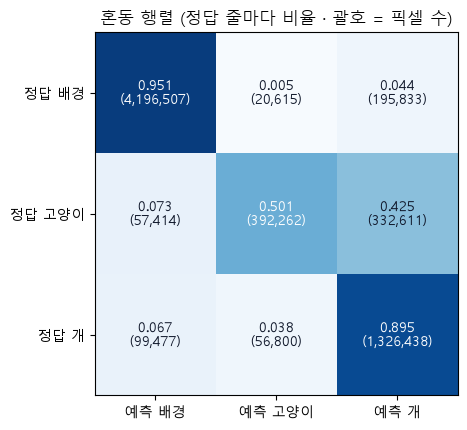

고양이 → 개 0.425 · 개 → 고양이 0.038


In [33]:
# ---------- 1-4 ----------
# 혼동 행렬 그림: 행 = 정답 · 열 = 예측 · 정답 줄마다 비율

plt.rcParams["font.family"] = "Malgun Gothic"                          # 한글
plt.rcParams["axes.unicode_minus"] = False                             # 음수 기호
rate = cm3.float() / cm3.sum(1, keepdim=True).float()                  # 정답 줄마다 합 1
fig, ax = plt.subplots(figsize=(5.2, 4.4))                             # 그림 크기
ax.imshow(rate, cmap="Blues", vmin=0, vmax=1)                          # 진할수록 많음
for r in range(3):                                                     # 정답 줄
    for k in range(3):                                                 # 예측 칸
        label = f"{rate[r, k]:.3f}\n({int(cm3[r, k]):,})"              # 비율 · 픽셀 수
        ax.text(k, r, label, ha="center", va="center", fontsize=10,    # 칸 가운데
                color="white" if rate[r, k] > 0.5 else "#0f172a")      # 진한 칸은 흰 글자
ax.set_xticks(range(3), [f"예측 {n}" for n in CLASSES], fontsize=10)   # 열 이름
ax.set_yticks(range(3), [f"정답 {n}" for n in CLASSES], fontsize=10)   # 행 이름
ax.set_title("혼동 행렬 (정답 줄마다 비율 · 괄호 = 픽셀 수)", fontsize=12)  # 제목
plt.tight_layout()                                                     # 여백
plt.show()                                                             # 표시
print(f"고양이 → 개 {rate[1, 2]:.3f} · 개 → 고양이 {rate[2, 1]:.3f}")  # 2클래스에서는 볼 수 없던 칸

In [34]:
from torchvision import tv_tensors     # 사진 · 정답 타입
from torchvision.transforms import v2  # 변환 (사진 · 정답 같이)
from PIL import ImageDraw              # 도형 그리기


# ---------- 2-1 ----------
# 사진만 뒤집고 정답은 그대로 두면? (에러가 나지 않음 → 숫자로 확인)
photo, target = load_pair("saint_bernard_146", three=False)         # 224×224 · 정답 0 · 1 · 255
photo_only = photo[:, ::-1].copy()                                  # 사진만 좌우 뒤집기
print("모양:", photo_only.shape, "·", target.shape, "→ 에러 없음")  # 모양은 같음
counts = [int((target == v).sum()) for v in (0, 1, IGNORE)]         # 값별 픽셀 수
print("정답 값 0 · 1 · 255 개수:", counts)                          # 개수도 같음

both = target[:, ::-1]                                    # 뒤집은 사진의 진짜 정답
pet = ((target == 1) & (both == 1)).sum() / ((target == 1) | (both == 1)).sum()  # 동물 IoU
print(f"그대로 둔 정답 ↔ 진짜 정답 동물 IoU: {pet:.2f}")  # 1보다 훨씬 작음


# ---------- 2-2 ----------
# torchvision v2: 그냥 텐서 vs Image · Mask로 감싸기 · Mask 크기 조정

img_t = torch.tensor(photo).permute(2, 0, 1)  # (3, 224, 224)
mask_t = torch.tensor(target)[None]           # (1, 224, 224)
flip = v2.RandomHorizontalFlip(p=1.0)         # 늘 뒤집음 (확인용)


def flp(u, v):                         # u가 v를 좌우로 뒤집은 것인지
    return torch.equal(u, v.flip(-1))  # 같으면 True


a, b = flip(img_t, mask_t)  # 그냥 텐서 두 개
print("그냥 텐서    · 사진 뒤집힘", flp(a, img_t), "· 정답 뒤집힘", flp(b, mask_t))  # 정답 그대로
a, b = flip(tv_tensors.Image(img_t), tv_tensors.Mask(mask_t))                        # 타입으로 감쌈
print("Image + Mask · 사진 뒤집힘", flp(a, img_t), "· 정답 뒤집힘", flp(b, mask_t))  # 둘 다

small = v2.Resize((56, 56), interpolation=v2.InterpolationMode.BILINEAR)   # bilinear를 지정해도
_, b = small(tv_tensors.Image(img_t), tv_tensors.Mask(mask_t))             # Mask는 nearest로 처리
bil = F.interpolate(mask_t[None].float(), size=(56, 56), mode="bilinear")  # 그냥 bilinear
kinds_mask, kinds_bil = torch.unique(b).tolist(), len(torch.unique(bil))   # 값 종류
print("Mask로 줄임 → 값", kinds_mask, "· 그냥 bilinear → 값", kinds_bil, "가지")  # 번호가 섞이나


# ---------- 2-3 ----------
# 회전의 빈 자리: 정답을 0(배경)으로 채울까 255(무시)로 채울까
rot0 = v2.RandomRotation(degrees=(25, 25))                            # 늘 25도 · 채움 기본값 0
_, m0 = rot0(tv_tensors.Image(img_t), tv_tensors.Mask(mask_t))        # 빈 모서리 = 배경
fills = {tv_tensors.Image: 0, tv_tensors.Mask: IGNORE}                # 사진 0 · 정답 255
rot255 = v2.RandomRotation(degrees=(25, 25), fill=fills)              # 타입마다 따로 채움
r_img, m1 = rot255(tv_tensors.Image(img_t), tv_tensors.Mask(mask_t))  # 빈 모서리 = 무시

bg = [(m == 0).float().mean().item() for m in (mask_t, m0, m1)]                # 배경 픽셀 비율
print("배경 비율: 원래 {:.2f} · 채움 0 {:.2f} · 채움 255 {:.2f}".format(*bg))  # 0이면 가짜 배경


def paint(m):                                 # 색칠용: 255 → 2
    return np.where(m[0] == IGNORE, 2, m[0])  # 0 배경 · 1 동물 · 2 무시

모양: (224, 224, 3) · (224, 224) → 에러 없음
정답 값 0 · 1 · 255 개수: [35166, 10804, 4206]
그대로 둔 정답 ↔ 진짜 정답 동물 IoU: 0.43
그냥 텐서    · 사진 뒤집힘 True · 정답 뒤집힘 False
Image + Mask · 사진 뒤집힘 True · 정답 뒤집힘 True
Mask로 줄임 → 값 [0, 1, 255] · 그냥 bilinear → 값 9 가지
배경 비율: 원래 0.70 · 채움 0 0.70 · 채움 255 0.56


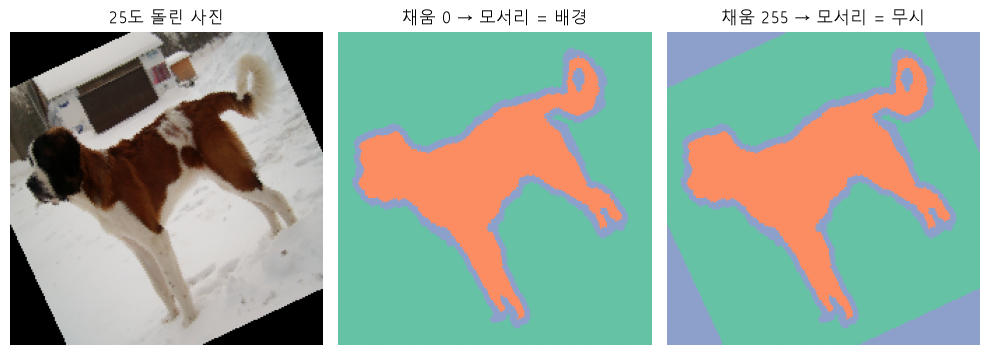

공 픽셀 221개 · 256×256으로 200번 자름 → 공이 남은 것 65번 (32%)
전부 남은 것: 41 번


In [35]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))      # 사진 · 정답 2개
ax[0].imshow(r_img.permute(1, 2, 0))                 # 돌린 사진
ax[0].set_title("25도 돌린 사진", fontsize=12)       # 빈 모서리 = 검정
pairs = [(ax[1], m0, "채움 0 → 모서리 = 배경"), (ax[2], m1, "채움 255 → 모서리 = 무시")]  # 정답 2개
for a, m, t in pairs:                                # 칸마다
    a.imshow(paint(m), cmap="Set2", vmin=0, vmax=7)  # 0 배경 · 1 동물 · 2 무시
    a.set_title(t, fontsize=12)                      # 제목
for a in ax:                                         # 축 지우기
    a.axis("off")                                    # 눈금 없음
plt.tight_layout()                                   # 여백
plt.show()                                           # 표시


# ---------- 2-4 ----------
# 무작위 자르기: 작은 물체(공)가 잘린 범위에 남는가 (원본: 미션 사진 · 여기서는 직접 그린 경기장)

field = Image.new("L", (640, 360), 0)                           # 360×640 정답 지도 (0 = 공 아님)
ImageDraw.Draw(field).ellipse((480, 60, 496, 76), fill=1)       # 지름 16 공 하나 (오른쪽 위)
ball = tv_tensors.Mask(torch.tensor(np.array(field)))           # 공 자리만 1
photo_f = tv_tensors.Image(torch.zeros(3, 360, 640, dtype=torch.uint8))  # 사진 자리 (값은 상관없음)
crop = v2.RandomCrop(256)                                       # 256×256 무작위 자르기
torch.manual_seed(0)                                            # 자르는 자리 고정
kept = [int(crop(photo_f, ball)[1].sum()) for _ in range(200)]  # 200번 자르고 남은 공 픽셀
n = sum(k > 0 for k in kept)                                    # 공이 조금이라도 남은 횟수
print(f"공 픽셀 {int(ball.sum())}개 · 256×256으로 200번 자름",  # 대부분 사라짐
      f"→ 공이 남은 것 {n}번 ({n / 200:.0%})")
print("전부 남은 것:", sum(k == int(ball.sum()) for k in kept), "번")  # 잘려서 일부만 남기도 함

In [36]:
# ---------- 3-1 ----------
# 작은 클래스는 손실에서 얼마나 작나: 학습 정답의 클래스별 픽셀 비율
cnt = torch.bincount(Ytr[Ytr != IGNORE], minlength=3).float()  # 경계 뺀 픽셀 수
for k, name in enumerate(CLASSES):                             # 클래스별
    print(f"{name}: {cnt[k] / cnt.sum():.3f}")                 # 비율
print(f"경계(255) 픽셀: {(Ytr == IGNORE).float().mean():.3f} (손실 · 평가에서 뺌)")  # 무시 비율
cat_imgs = sum(SPECIES[n] == 1 for n in TRAIN[:1200])          # 학습 사진 중 고양이
print(f"학습 사진: 고양이 {cat_imgs} · 개 {1200 - cat_imgs}")  # 사진 수부터 차이


# ---------- 3-2 ----------
# 장난감 32×32: 3×3 물체(9픽셀 · 0.9%) · 예측 A 전부 배경 · B 정확히 · C 7×7로 크게
toy_t = torch.zeros(32, 32, dtype=torch.long)  # 정답 지도
toy_t[14:17, 14:17] = 1                        # 물체 9픽셀


def toy_logits(obj):                   # 물체라고 본 자리 [0, 8] · 나머지 [8, 0]
    lg = torch.zeros(2, 32, 32)        # (클래스, H, W)
    lg[0] = 8.0                        # 기본: 배경 확신
    lg[0][obj], lg[1][obj] = 0.0, 8.0  # 물체 자리: 물체 확신
    return lg                          # 점수


def soft_dice(p, t):                                         # 확률로 계산한 물체 Dice
    return (2 * (p * t).sum() / (p.sum() + t.sum())).item()  # 2·겹침 ÷ (예측 + 정답)


exact = toy_t == 1                                                              # 정확한 물체 자리
big = torch.zeros(32, 32, dtype=torch.bool)                                     # 7×7 = 49픽셀
big[12:19, 12:19] = True                                                        # 둘레까지 크게
print("예측           | CE 평균 | 물체 픽셀 CE | 물체 soft Dice")               # 머리
cases = [("A 전부 배경  ", torch.zeros_like(exact)), ("B 정확히     ", exact),  # 놓침 · 정확
         ("C 7×7로 크게", big)]                                                 # 넘치게
for name, m in cases:                                                           # 예측 세 가지
    lg = toy_logits(m)                                                          # 예측 점수
    ce = F.cross_entropy(lg[None], toy_t[None], reduction="none")[0]            # 픽셀별 CE 지도
    dice = soft_dice(lg.softmax(0)[1], exact.float())                           # 물체 확률로 Dice
    print(f"{name}   | {ce.mean():.3f}   | {ce[exact].mean():.3f}        | {dice:.3f}")  # 한 줄


# ---------- 3-3 ----------
# Dice와 IoU: 같은 TP · FP · FN으로 셈 (Day1의 6×6 장난감)
TP, FP, FN = 4, 5, 5                # 겹침 · 잘못 칠함 · 놓침
iou = TP / (TP + FP + FN)           # IoU
dice = 2 * TP / (2 * TP + FP + FN)  # Dice
from_iou = 2 * iou / (1 + iou)      # IoU로 Dice 계산
print(f"IoU {iou:.2f} · Dice {dice:.2f} · 2·IoU ÷ (1 + IoU) = {from_iou:.2f}")  # 같은 정보


# ---------- 3-4 ----------
# 지표 Dice → 손실: argmax는 기울기가 끊기므로 확률로 계산한 soft Dice
lg = toy_logits(big).clone().requires_grad_(True)                        # C 예측 · 기울기 추적
hard = lg.argmax(0)                                                      # 0/1로 자른 예측
print("argmax 결과의 grad_fn:", hard.grad_fn)                            # None → 손실로 못 씀
p_obj = lg.softmax(0)[1]                                                 # 물체 확률 (그대로 둠)
loss_dice = 1 - 2 * (p_obj * exact).sum() / (p_obj.sum() + exact.sum())  # soft Dice 손실
loss_dice.backward()                                                     # 역전파
print(f"soft Dice 손실 {loss_dice.item():.3f} · 기울기 있음: {lg.grad is not None}")  # 학습 가능

배경: 0.661
고양이: 0.128
개: 0.211
경계(255) 픽셀: 0.118 (손실 · 평가에서 뺌)
학습 사진: 고양이 413 · 개 787
예측           | CE 평균 | 물체 픽셀 CE | 물체 soft Dice
A 전부 배경     | 0.071   | 8.000        | 0.001
B 정확히        | 0.000   | 0.000        | 0.981
C 7×7로 크게   | 0.313   | 0.000        | 0.309
IoU 0.29 · Dice 0.44 · 2·IoU ÷ (1 + IoU) = 0.44
argmax 결과의 grad_fn: None
soft Dice 손실 0.691 · 기울기 있음: True


검증 460장 중 종을 틀린 비율 10% 초과 113장 · 50% 초과 72장
Siamese_114            틀린 비율 1.00 (고양이→개 3,576 · 개→고양이 0)
Sphynx_199             틀린 비율 1.00 (고양이→개 6,520 · 개→고양이 0)
Birman_151             틀린 비율 1.00 (고양이→개 2,199 · 개→고양이 0)
Bombay_102             틀린 비율 1.00 (고양이→개 4,938 · 개→고양이 0)
Siamese_175            틀린 비율 1.00 (고양이→개 4,534 · 개→고양이 0)
Bengal_128             틀린 비율 1.00 (고양이→개 6,762 · 개→고양이 0)


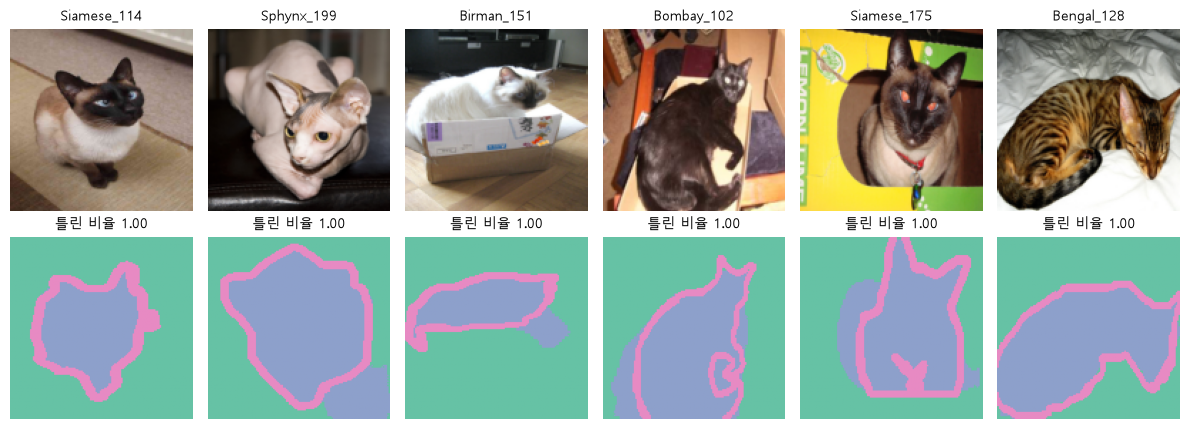

In [37]:
# ---------- 4-1 ----------
# 사진마다 '종을 틀린 동물 픽셀' 비율 → 많이 틀린 사진부터 보기
cat_as_dog = ((Yva == 1) & (P3 == 2)).flatten(1).sum(1)            # 사진마다 고양이 → 개
dog_as_cat = ((Yva == 2) & (P3 == 1)).flatten(1).sum(1)            # 개 → 고양이
pet_px = ((Yva == 1) | (Yva == 2)).flatten(1).sum(1).clamp_min(1)  # 동물 픽셀 (0 나눗셈 방지)
mix = (cat_as_dog + dog_as_cat).float() / pet_px.float()           # 종을 틀린 비율
n10, n50 = int((mix > 0.1).sum()), int((mix > 0.5).sum())          # 10% · 50% 넘는 사진 수
print(f"검증 {len(VAL)}장 중 종을 틀린 비율 10% 초과 {n10}장 · 50% 초과 {n50}장")  # 분포
worst = torch.argsort(mix, descending=True)[:6].tolist()           # 가장 많이 틀린 6장
for j in worst:                                                    # 한 줄씩
    c2d, d2c = int(cat_as_dog[j]), int(dog_as_cat[j])              # 두 방향 픽셀
    print(f"{VAL[j]:22} 틀린 비율 {mix[j]:.2f} (고양이→개 {c2d:,} · 개→고양이 {d2c:,})")  # 한 장

fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))                 # 위: 사진 · 아래: 예측
for c, j in enumerate(worst):                                   # 6장
    ax[0, c].imshow(load_pair(VAL[j], 128)[0])                  # 사진
    ax[0, c].set_title(VAL[j][:14], fontsize=10)                # 이름
    shown = torch.where(Yva[j] == IGNORE, 3, P3[j])             # 예측 (경계 자리는 3)
    ax[1, c].imshow(shown, cmap="Set2", vmin=0, vmax=7)         # 번호별 색
    ax[1, c].set_title(f"틀린 비율 {mix[j]:.2f}", fontsize=10)  # 비율
for a in ax.flat:                                               # 축 지우기
    a.axis("off")                                               # 눈금 없음
plt.tight_layout()                                              # 여백
plt.show()                                                      # 표시

In [38]:
from collections import deque             # 너비 우선 탐색
from torchvision.models import detection  # Mask R-CNN 모델 · 가중치


# ---------- 5-1 ----------
# semantic 정답으로 '몇 마리?'에 답할 수 있나: 붙어 있는 픽셀 덩어리 세기


def count_blobs(mask):                                            # 상하좌우로 닿은 True 덩어리 수
    seen, n = np.zeros_like(mask, dtype=bool), 0                  # 방문 표시 · 개수
    for y, x in zip(*np.nonzero(mask)):                           # True 픽셀마다
        if seen[y, x]:                                            # 이미 센 덩어리
            continue                                              # 건너뜀
        n += 1                                                    # 새 덩어리
        seen[y, x], q = True, deque([(y, x)])                     # 시작점
        while q:                                                  # 이웃으로 퍼짐
            cy, cx = q.popleft()                                  # 꺼내기
            for ny, nx in ((cy - 1, cx), (cy + 1, cx), (cy, cx - 1), (cy, cx + 1)):  # 상하좌우
                inside = 0 <= ny < mask.shape[0] and 0 <= nx < mask.shape[1]  # 지도 안
                if inside and mask[ny, nx] and not seen[ny, nx]:  # 동물 · 처음
                    seen[ny, nx] = True                           # 방문
                    q.append((ny, nx))                            # 다음 차례
    return n                                                      # 덩어리 수


inst_name = "leonberger_107"         # 개 여러 마리 · 사람이 있는 사진
inst_photo = np.array(Image.open(DATA / "images" / f"{inst_name}.jpg").convert("RGB"))  # 원본 크기
inst_tri = np.array(Image.open(DATA / "annotations" / "trimaps" / f"{inst_name}.png"))  # 원본 정답
n_blob = count_blobs(inst_tri == 1)  # 동물 픽셀 덩어리
print("사진 크기:", inst_photo.shape, "· 동물(값 1) 덩어리 수:", n_blob)  # 개체 수가 아님


# ---------- 5-2 ----------
# Mask R-CNN (COCO 학습 가중치 · 추론만): 개체마다 박스 · 클래스 · 점수 · 마스크

mr_w = detection.MaskRCNN_ResNet50_FPN_Weights.COCO_V1        # COCO 가중치 (캐시에 없으면 약 170MB)
mrcnn = detection.maskrcnn_resnet50_fpn(weights=mr_w).eval()  # 평가 모드 (CPU)
coco_names = mr_w.meta["categories"]                          # 번호 → 이름
inst_x = torch.tensor(inst_photo).permute(2, 0, 1).float() / 255  # 0~1 (정규화는 모델 안에서)
with torch.no_grad():                                         # 추론
    mr_out = mrcnn([inst_x])[0]                               # 사진 목록 → 사진마다 dict
for k, v in mr_out.items():                                   # 키 · 모양
    print(f"{k:7}", tuple(v.shape))                           # boxes · labels · scores · masks

print("① 탐지 점수 기준만 바꿈 (마스크 기준 0.5 고정)")           # 개체를 고르는 기준
for th in (0.1, 0.5, 0.9):                                        # 낮음 · 기본 · 높음
    keep = mr_out["scores"] >= th                                 # 남길 개체
    found = ", ".join(coco_names[i] for i in mr_out["labels"][keep].tolist())  # 이름 목록
    print(f"   {th} 이상 → {int(keep.sum())}개:", found)          # 개수 · 이름
print("② 마스크 확률 기준만 바꿈 (0번 개체)")                     # 픽셀을 고르는 기준
prob0 = mr_out["masks"][0, 0]                                     # 0번 개체의 픽셀별 확률
for th in (0.3, 0.5, 0.7):                                        # 기준 3개
    print(f"   {th} 이상 → 픽셀 {int((prob0 >= th).sum()):,}개")  # 경계만 안팎으로

사진 크기: (500, 333, 3) · 동물(값 1) 덩어리 수: 1


boxes   (21, 4)
labels  (21,)
scores  (21,)
masks   (21, 1, 500, 333)
① 탐지 점수 기준만 바꿈 (마스크 기준 0.5 고정)
   0.1 이상 → 16개: dog, person, dog, person, dog, dog, person, dog, person, person, person, dog, horse, person, handbag, dog
   0.5 이상 → 8개: dog, person, dog, person, dog, dog, person, dog
   0.9 이상 → 5개: dog, person, dog, person, dog
② 마스크 확률 기준만 바꿈 (0번 개체)
   0.3 이상 → 픽셀 28,572개
   0.5 이상 → 픽셀 27,021개
   0.7 이상 → 픽셀 25,530개


박스 가지: ['box_roi_pool', 'box_head', 'box_predictor']
마스크 가지: ['mask_roi_pool', 'mask_head', 'mask_predictor']


마스크 헤드 출력: (21, 91, 28, 28) ← 개체 × 클래스 자리 91 × 28 × 28
돌려받는 masks: (21, 1, 500, 333) ← 고른 클래스 하나 · 사진 크기


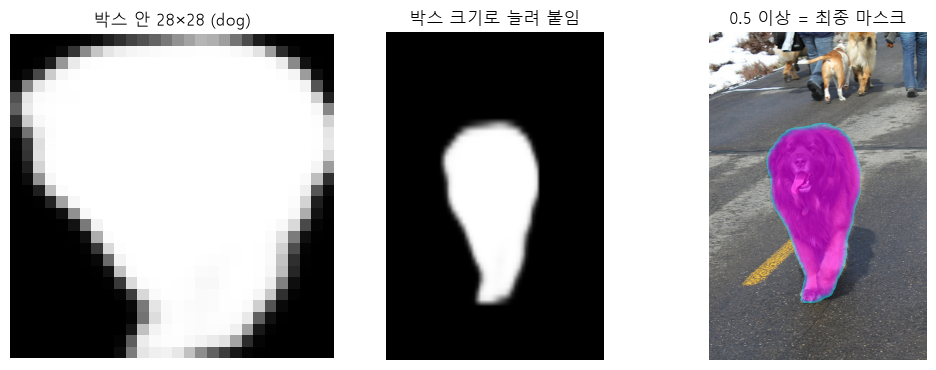

loss_classifier   0.009
loss_box_reg      0.017
loss_mask         0.165
loss_objectness   0.001
loss_rpn_box_reg  0.002


In [39]:
# ---------- 5-3 ----------
# 안을 열어 보기: roi_heads의 마스크 헤드 출력 = 박스마다 클래스 수 × 28 × 28
parts = [n for n, _ in mrcnn.roi_heads.named_children()]      # roi_heads 안 층 이름
print("박스 가지:", parts[:3])                                # 자르기 · 머리 · 예측
print("마스크 가지:", parts[3:])                              # 같은 3단 구조
seen = {}                                                     # 훅이 담을 곳
hook = mrcnn.roi_heads.mask_predictor.register_forward_hook(  # 마스크 헤드 출력 가로채기
    lambda mod, inp, out: seen.update(logits=out.detach()))   # 출력 저장
with torch.no_grad():                                         # 다시 추론
    mrcnn([inst_x])                                           # 같은 사진
hook.remove()                                                 # 훅 제거
print("마스크 헤드 출력:", tuple(seen["logits"].shape),       # 클래스마다 28×28
      "← 개체 × 클래스 자리 91 × 28 × 28")
print("돌려받는 masks:", tuple(mr_out["masks"].shape),        # 붙인 결과
      "← 고른 클래스 하나 · 사진 크기")

k0 = int(mr_out["labels"][0])                                      # 0번 개체가 고른 클래스
small = seen["logits"][0, k0].sigmoid()                            # 그 클래스의 28×28 확률
fig, ax = plt.subplots(1, 3, figsize=(10, 3.8))                    # 28×28 · 붙인 확률 · 최종
ax[0].imshow(small, cmap="gray", vmin=0, vmax=1)                   # ① ② 박스 안 확률
ax[0].set_title(f"박스 안 28×28 ({coco_names[k0]})", fontsize=12)  # 제목
ax[1].imshow(prob0, cmap="gray", vmin=0, vmax=1)                   # ③ 박스 크기로 늘려 붙임
ax[1].set_title("박스 크기로 늘려 붙임", fontsize=12)              # 제목
ax[2].imshow(inst_photo)                                           # 사진 위에
ax[2].imshow(np.ma.masked_where(prob0 < 0.5, prob0), cmap="cool", alpha=0.6)  # 0.5 이상만
ax[2].set_title("0.5 이상 = 최종 마스크", fontsize=12)             # 제목
for a in ax:                                                       # 축 지우기
    a.axis("off")                                                  # 눈금 없음
plt.tight_layout()                                                 # 여백
plt.show()                                                         # 표시


# ---------- 5-4 ----------
# 학습 모드: 정답(박스 · 클래스 · 마스크)을 주면 손실 5개를 dict로 돌려줌 (가중치는 안 바꿈)
one_photo, one_t = load_pair("saint_bernard_146", three=False)  # 개 한 마리 사진
one_mask = torch.tensor(one_t == 1)                             # 동물 픽셀
ys, xs = torch.nonzero(one_mask, as_tuple=True)                 # 마스크 좌표
box = [xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]          # 마스크를 감싸는 박스
target = {"boxes": torch.tensor([box], dtype=torch.float32),    # 개체마다 박스
          "labels": torch.tensor([coco_names.index("dog")]),    # 개체마다 클래스
          "masks": one_mask[None].to(torch.uint8)}              # (개체 수, H, W)
torch.manual_seed(SEED)                                         # 학습 모드 후보 뽑기 고정
mrcnn.train()                                                   # 학습 모드
losses = mrcnn([torch.tensor(one_photo).permute(2, 0, 1).float() / 255], [target])  # 손실 dict
mrcnn.eval()                                                    # 다시 평가 모드
for k, v in losses.items():                                     # 이름 · 값
    print(f"{k:17} {v.item():.3f}")                             # 분류 · 박스 · 마스크 · RPN 2개

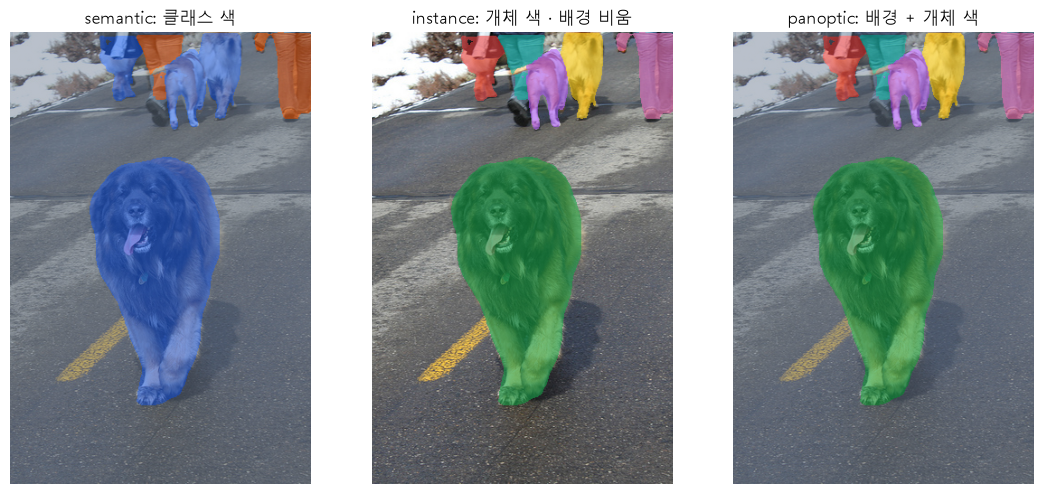

점수 0.8 이상 6개: dog, person, dog, person, dog, dog
자기 polygon 픽셀  : [4961, 121, 48000]
json 순서로 칠함   : [1640, 0, 48000]
잔디 먼저 · 공 마지막: [4961, 121, 44558]


In [40]:
import matplotlib  # 색 변환
import hashlib     # 파일 내용 지문


# ---------- 6-1 ----------
# 같은 Mask R-CNN 출력을 semantic · instance · panoptic으로 칠하기

sure = torch.nonzero(mr_out["scores"] >= 0.8).flatten().tolist()                # 점수 0.8 이상 개체
H, W = inst_photo.shape[:2]                                                     # 사진 크기
cls_color = {"dog": "#2563eb", "person": "#ea580c"}  # semantic: 클래스마다 한 색
palette = ["#16a34a", "#f472b6", "#facc15", "#14b8a6", "#a855f7", "#ef4444"]    # 개체마다 다른 색
views = [np.zeros((H, W, 4)) for _ in range(3)]  # semantic · instance · panoptic
views[0][:] = views[2][:] = matplotlib.colors.to_rgba("#64748b", 0.45)          # 배경(stuff) = 회색
for j, i in enumerate(sure):                                                    # 개체마다
    m = (mr_out["masks"][i, 0] >= 0.5).numpy()                                  # 0.5 이상 마스크
    name = coco_names[mr_out["labels"][i]]                                      # 클래스 이름
    views[0][m] = matplotlib.colors.to_rgba(cls_color.get(name, "white"), 0.6)  # 클래스 색
    views[1][m] = views[2][m] = matplotlib.colors.to_rgba(palette[j % 6], 0.6)  # 개체 색
fig, ax = plt.subplots(1, 3, figsize=(11, 5))                                   # 세 방식
titles = ["semantic: 클래스 색", "instance: 개체 색 · 배경 비움",               # 제목
          "panoptic: 배경 + 개체 색"]
for a, v, t in zip(ax, views, titles):                                          # 세 칸
    a.imshow(inst_photo)                                                        # 사진
    a.imshow(v)                                                                 # 덮어 칠함
    a.set_title(t, fontsize=12)                                                 # 제목
    a.axis("off")                                                               # 눈금 없음
plt.tight_layout()                                                              # 여백
plt.show()                                                                      # 표시
kept = ", ".join(coco_names[mr_out["labels"][i]] for i in sure)                 # 이름 목록
print(f"점수 0.8 이상 {len(sure)}개:", kept)                                    # 개체 목록


# ---------- 6-2 ----------
# 미션 ③ 한 픽셀에 답이 둘이면: polygon을 json 순서대로 덮어 칠하면 작은 공이 사라짐 (직접 만든 예)
anns = [("Team A", [(150, 80), (190, 80), (190, 200), (150, 200)]),  # (클래스, polygon) · json 순서
        ("Ball", [(196, 186), (206, 186), (206, 196), (196, 196)]),  # 선수 발밑의 작은 공
        ("Ground", [(0, 120), (400, 120), (400, 240), (0, 240)])]    # 넓은 잔디 (마지막)
own = {}  # annotation마다 자기 polygon만 칠한 지도
for k, (name, poly) in enumerate(anns):                              # 하나씩
    m = Image.new("L", (400, 240), 0)                                # 빈 지도
    ImageDraw.Draw(m).polygon(poly, fill=1)                          # polygon 안 = 1
    own[k] = np.array(m, dtype=bool)                                 # True/False 지도


def paint_order(order):            # 주어진 순서로 덮어 칠한 뒤 남은 픽셀 수
    lab = np.full((240, 400), -1)  # -1 = 안 칠함
    for k in order:                # 뒤에 칠한 것이 위
        lab[own[k]] = k            # 덮어쓰기
    return [int((lab == k).sum()) for k in range(len(anns))]  # annotation별 남은 픽셀


print("자기 polygon 픽셀  :", [int(own[k].sum()) for k in range(3)])  # 원래 넓이
print("json 순서로 칠함   :", paint_order([0, 1, 2]))    # 잔디가 마지막 → 공 · 발 사라짐
print("잔디 먼저 · 공 마지막:", paint_order([2, 0, 1]))  # 작은 것을 위로

In [41]:
# ---------- 6-3 ----------
# 미션 ④ 어느 사진끼리 나누나: 내용이 같은 파일을 묶고 묶음 단위로 train / test (직접 만든 예)

files = {f"Frame ({i})": bytes([i % 7]) * 64 for i in range(1, 15)}           # 14장 · 내용 7가지
groups = {}                                                                   # 지문 → 파일 이름들
for name, raw in files.items():                                               # 파일마다
    groups.setdefault(hashlib.md5(raw).hexdigest(), []).append(name)          # 같은 내용끼리 모음
bundles = sorted(groups.values())                                             # 묶음 목록
print("파일", len(files), "개 → 묶음", len(bundles), "개 · 예:", bundles[0])  # 같은 사진 묶음
rng = random.Random(SEED)                                                     # 나누기 고정
rng.shuffle(bundles)                                                          # 묶음 단위로 섞기
test_ids = [n for b in bundles[:2] for n in b]                                # 묶음 2개 = test
train_ids = [n for b in bundles[2:] for n in b]                               # 나머지 = train
digest = {n: hashlib.md5(raw).hexdigest() for n, raw in files.items()}        # 파일마다 지문
same = {digest[n] for n in train_ids} & {digest[n] for n in test_ids}         # 양쪽에 다 있는 지문
assert not same, "train과 test에 같은 사진이 있음"                            # 새는 사진 없음 확인
print("train", len(train_ids), "장 · test", len(test_ids),                    # 결과
      "장 · 겹치는 내용 0 (assert 통과)")

파일 14 개 → 묶음 7 개 · 예: ['Frame (1)', 'Frame (8)']
train 10 장 · test 4 장 · 겹치는 내용 0 (assert 통과)


100장 · 품종 37개 · 고양이 39 · 개 61 · 입력 (100, 3, 128, 128)


S100 처음부터 · best epoch 6 · val 손실 0.699


P100 ImageNet · best epoch 12 · val 손실 0.428
              | 배경   | 고양이 | 개     | mIoU


S100 처음부터 | 0.725 | 0.006 | 0.401 | 0.377


P100 ImageNet | 0.882 | 0.454 | 0.605 | 0.647


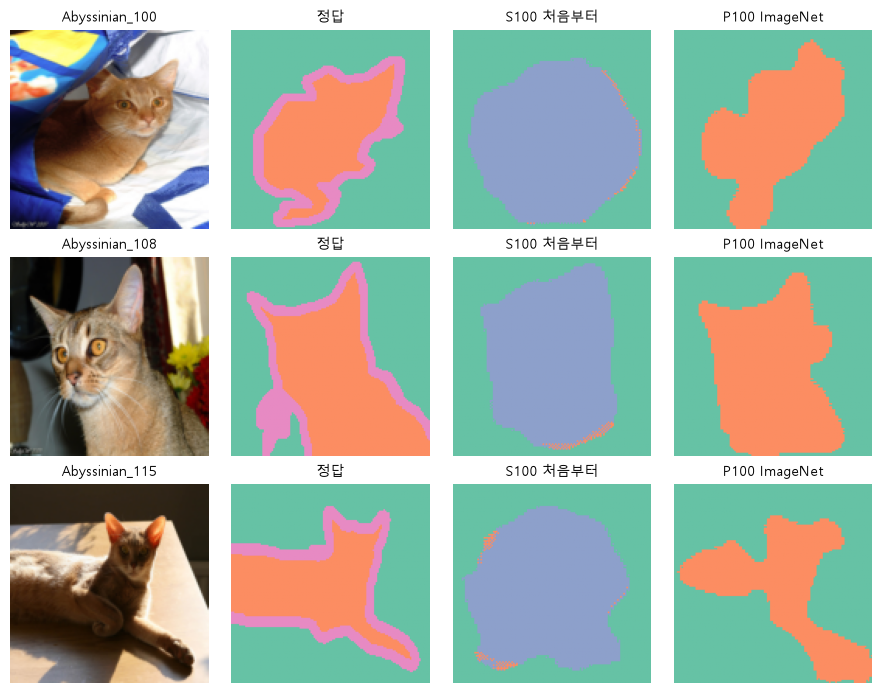

In [42]:
# ---------- 7. 종합 실습 ----------
# 1단계: 학습 사진 100장 고르기 (품종 37개가 모두 들어가게) · 나머지 조건 고정
by_breed = {}                                                               # 품종 → 사진 이름들
for n in TRAIN:                                                             # 학습 후보
    by_breed.setdefault(n.rsplit("_", 1)[0], []).append(n)                  # 이름 앞부분 = 품종
rng = random.Random(SEED)                                                   # 고르기 고정
ids100 = [rng.choice(v) for v in by_breed.values()]                         # 품종마다 1장 (37장)
rest = [n for n in TRAIN if n not in set(ids100)]                           # 남은 사진
ids100 += rng.sample(rest, 100 - len(ids100))                               # 63장 더 → 100장
X100, Y100 = load_set(ids100)                                               # 128×128 텐서
cats = sum(SPECIES[n] == 1 for n in ids100)                                 # 고양이 수
print(f"100장 · 품종 {len(by_breed)}개 · 고양이 {cats} · 개 {100 - cats}",  # 확인
      f"· 입력 {tuple(X100.shape)}")


# 2단계: 같은 구조 · 같은 조건 · 시작 가중치만 다르게 (처음부터 vs ImageNet) · 40 epoch
runs = {}                                                             # 결과 모음
for run, pre in [("S100 처음부터", False), ("P100 ImageNet", True)]:  # 바꾸는 것은 하나
    torch.manual_seed(SEED)                                           # 디코더 초기값 같게
    model = ResUNet(3, pretrained=pre).to(device)                     # 구조는 같음
    best, hist = train(model, X100, Y100, epochs=40, Xv=Xva, Yv=Yva)  # val 손실 최저 = best
    runs[run] = (model, best, hist)                                   # 저장
    print(f"{run} · best epoch {hist.index(min(hist)) + 1} · val 손실 {min(hist):.3f}")  # 기록


# 3단계: best를 다시 불러와 평가 (저장만 하고 끝내지 않기) · 클래스별 IoU
print("              | 배경   | 고양이 | 개     | mIoU")   # 머리
for run, (model, best, hist) in runs.items():              # 두 모델
    model.load_state_dict(best)                            # best 가중치로 덮어씀
    pred, cm, _ = evaluate(model, Xva, Yva)                # 검증 460장
    inter = cm.diag().float()                              # TP
    iou = inter / (cm.sum(0) + cm.sum(1) - inter).float()  # 클래스별 IoU
    runs[run] = (model, pred, iou)                         # 그림용으로 예측 보관
    print(f"{run} | " + " | ".join(f"{v:.3f}" for v in iou) + f" | {iou.mean():.3f}")  # 한 줄


# 4단계: 같은 검증 사진 3장의 정답 · 두 모델 예측
show = [0, 1, 2]                                                       # 검증 앞 3장
fig, ax = plt.subplots(3, 4, figsize=(9, 7))                           # 사진 · 정답 · 모델 2개
for r, j in enumerate(show):                                           # 한 줄에 한 장
    gt = torch.where(Yva[j] == IGNORE, 3, Yva[j])                      # 정답 (경계 = 3)
    panels = [(load_pair(VAL[j], 128)[0], VAL[j][:16]), (gt, "정답")]  # 사진 · 정답
    panels += [(runs[k][1][j], k) for k in runs]                       # 두 모델 예측
    for c, (img, title) in enumerate(panels):                          # 4칸
        ax[r, c].imshow(img, cmap=None if c == 0 else "Set2", vmin=0, vmax=7)  # 번호별 색
        ax[r, c].set_title(title, fontsize=10)                         # 제목
        ax[r, c].axis("off")                                           # 눈금 없음
plt.tight_layout()                                                     # 여백
plt.show()                                                             # 표시